# Cấu hình 1 (C1) — v10: Ảnh → VLM (fine-tune) → nhãn + mô tả → LLM (KHÔNG RAG) → Tư vấn → **Đo ảo giác**

```
Ảnh -> VLM (Qwen2.5-VL-3B + LoRA checkpoint-1023) -> nhãn + mô tả JSON (lesion_color, lesion_shape, distribution, severity)
nhãn + mô tả + question -> LLM (Qwen2.5-7B-Instruct, KHÔNG có tài liệu) -> "Chẩn đoán: ..." + tư vấn xử lý
tư vấn -> [Mức 1: chỉ số tự động] + [Mức 2: kiểm chứng từng mệnh đề với tài liệu tham chiếu] -> tỉ lệ ảo giác
```



| Thành phần | Nhận gì | Cho ra gì |
|---|---|---|
| VLM | **Chỉ ảnh** + 1 câu lệnh cố định | nhãn bệnh + mô tả JSON |
| LLM | nhãn + mô tả + question | "Chẩn đoán: ..." + tư vấn (tiếng Việt) |
| `test.jsonl` | chỉ dùng lấy *question* | không đọc đáp án |
| `disease_reference.json` | (mới) tri thức chuẩn từng bệnh do chuyên gia/tài liệu | **chỉ dùng để chấm**, không đưa vào LLM |

## 0. Cài đặt

In [1]:
!pip uninstall -y transformers torchao -q
!pip install -q "transformers==4.57.1"
!pip install -q -U accelerate peft bitsandbytes qwen-vl-utils einops "pillow==11.0.0" --no-cache-dir

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 1.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 63.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 17.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 20.4 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.26.0 requires huggingface-hub<2.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.40.0 requires huggingface-hub<2.0,>=1.23.0, but you have huggingface-hub 0.36.2 which is incompatible.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.4/4.4 MB 41.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 394.3/394.3 kB 214.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 835.4/835.4 kB 118.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

## 1. Cấu hình (chỉ cần kiểm tra các dòng đánh dấu `<-`)

In [2]:
import os, sys, gc, time, random, re, json, math, glob, unicodedata
from collections import defaultdict
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm

# ====== ĐƯỜNG DẪN ======
DATASET_ROOT     = "/kaggle/input/datasets/hhaaad/a-adurian-leaf-diseases1/Durian_Leaf_Diseases"
TEST_JSONL_PATH  = "/kaggle/input/datasets/hhaaad/testjson05/test.jsonl"   # CHỈ dùng khi ĐÁNH GIÁ: lấy question của tập test (đầu vào LLM). Không đưa gì vào VLM, không đọc đáp án
VLM_BASE_MODEL   = "Qwen/Qwen2.5-VL-3B-Instruct"
VLM_ADAPTER_PATH = "/kaggle/input/notebooks/hauhoccode/vlm-train/qwen2.5-vl-durian-adapter/checkpoint-1023"
LLM_NAME         = "Qwen/Qwen2.5-7B-Instruct"
OUT_DIR          = "/kaggle/working/config1"
REFERENCE_PATH   = "/kaggle/input/datasets/hhaaad/testrag03/disease_reference.json"   # <- ĐƯỜNG DẪN file disease_reference.json (tri thức chuẩn để chấm ảo giác, xem mục 7). Chưa có thì để None: chỉ chạy Mức 1
TRAIN_JSONL_PATH = None   # <- nếu lấy lại được train.jsonl thì điền đường dẫn (gốc: /kaggle/input/datasets/hauhoccode/dataset-finetune/train.jsonl). None = dùng kiểm tra dự phòng
VAL_JSONL_PATH   = None   # <- tương tự, val.jsonl
EXCLUDE_DUP_TEST = True   # <- True: loại khỏi tập đánh giá các ảnh test có NỘI DUNG (md5) trùng ảnh ở train/val (tránh thổi phồng accuracy VLM)

# ====== PHẠM VI CHẠY ======
EVAL_LIMIT = None     # <- None = FULL 402 ảnh. Đặt 8 để chạy thử (nên chạy thử trước, xem nhãn VLM trả về có đúng dạng không)
SEED       = 42
RESUME     = True

# ====== VLM ======
VLM_MAX_PIXELS = 640 * 28 * 28   # LƯU Ý: lúc train KHÔNG đặt max_pixels (mặc định processor, rất lớn). Xem ô "3c" để biết ảnh test có bị hạ độ phân giải không
VLM_MIN_PIXELS = 64 * 28 * 28
VLM_BATCH      = 8
VLM_DESC_MAX_NEW_TOKENS  = 200   # mô tả JSON
VLM_LABEL_MAX_NEW_TOKENS = 64    # nhãn bệnh (ngắn)
# Câu lệnh CỐ ĐỊNH cho VLM. Theo sơ đồ C1, VLM chỉ nhận ẢNH: không lấy bất cứ gì từ test.jsonl.
VLM_LABEL_PROMPT = "Lá sầu riêng trong ảnh này bị bệnh gì?"   # <- nên khớp dạng câu hỏi task 'disease' lúc train (xem train.jsonl)
VLM_DESC_PROMPT  = "Anh xem giúp tôi các vết bệnh trên lá này có đặc điểm hình thái cụ thể như thế nào?"   # <- nên khớp dạng câu lệnh task 'attributes' lúc train; cần cho JSON đủ 4 trường

# QUESTION đưa vào LLM (đầu vào thứ 3 của LLM trong sơ đồ C1):
USE_TEST_QUESTIONS = True    # True: lấy question của từng ảnh trong test.jsonl (task 'disease'). False: mọi ảnh dùng NEUTRAL_QUESTION.
NEUTRAL_QUESTION = "Lá sầu riêng nhà tôi bị như thế này, đây là bệnh gì và cần xử lý ra sao?"   # dùng khi ảnh không có question trong test.jsonl (hoặc USE_TEST_QUESTIONS=False)

# ====== LLM ======
LLM_BATCH               = 24
LLM_MAX_NEW_TOKENS      = 512    # độ dài tối đa của câu tư vấn đầy đủ
LLM_DIAG_MAX_NEW_TOKENS = 48     # chạy nhanh chỉ dòng "Chẩn đoán:" cho TOÀN BỘ ảnh (đo accuracy)
ADVICE_N = 120   # <- LẦN ĐẦU để 8 (chạy thử). Chạy ổn thì đổi thành 120 (20 ảnh/lớp) rồi chạy lại: kết quả của 8 ảnh được dùng lại. None = tất cả 402 ảnh
MAX_CLAIMS = 15  # số mệnh đề tối đa kiểm chứng trên mỗi câu tư vấn

assert torch.cuda.is_available(), "Cần bật GPU (Kaggle: Settings -> Accelerator -> GPU T4)"
VLM_DTYPE = torch.bfloat16    # giữ nguyên để khớp adapter
_cc = torch.cuda.get_device_capability(0)
LLM_DTYPE = torch.bfloat16 if _cc[0] >= 8 else torch.float16    # T4 không có lõi bf16 -> dùng fp16 cho LLM
print("VLM dtype:", VLM_DTYPE, "| LLM dtype:", LLM_DTYPE, "| compute capability:", _cc)

os.makedirs(OUT_DIR, exist_ok=True)
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
print("GPU:", torch.cuda.get_device_name(0), "| VRAM:", round(torch.cuda.get_device_properties(0).total_memory / 2**30, 1), "GiB")

def free_cuda():
    gc.collect()
    torch.cuda.empty_cache()

VLM dtype: torch.bfloat16 | LLM dtype: torch.float16 | compute capability: (7, 5)
GPU: Tesla T4 | VRAM: 14.6 GiB


## 2. Hàm tiện ích

In [3]:
# ====== QUY ĐỊNH NHÃN Anh -> Việt ======
ORDER = ["Algal", "Blight", "Colletotrichum", "Phomopsis", "Rhizoctonia", "Healthy"]
DISEASE_MAP = {
    "Algal": dict(
        display="Bệnh đốm rong (Cephaleuros virescens)", short="đốm rong",
        keywords=["bệnh đốm rong", "đốm rong", "cephaleuros virescens", "cephaleuros",
                  "bệnh rong tảo", "rong tảo", "bệnh tảo lá", "tảo lá", "đốm tảo", "algal leaf spot", "algal", "bệnh tảo"]),
    "Blight": dict(
        display="Bệnh cháy lá, chưa xác định tác nhân (Leaf_Blight)", short="cháy lá chưa rõ tác nhân",
        keywords=["cháy lá chưa rõ tác nhân", "chưa xác định tác nhân", "bệnh cháy lá", "cháy lá", "leaf blight"]),
    "Colletotrichum": dict(
        display="Bệnh thán thư (Colletotrichum sp.)", short="thán thư",
        keywords=["bệnh thán thư", "thán thư", "colletotrichum sp", "anthracnose", "colletotrichum"]),
    "Phomopsis": dict(
        display="Bệnh đốm lá (Phomopsis sp.)", short="đốm lá do Phomopsis",
        keywords=["đốm lá do phomopsis", "bệnh đốm lá do phomopsis", "phomopsis durionis", "phomopsis sp",
                  "bệnh do nấm phomopsis", "nấm phomopsis", "phomopsis leaf blight", "phomopsis"]),
    "Rhizoctonia": dict(
        display="Bệnh cháy lá, chết ngọn (Rhizoctonia sp.)", short="cháy lá và chết ngọn do Rhizoctonia",
        keywords=["cháy lá và chết ngọn do rhizoctonia", "cháy lá, chết ngọn", "chết ngọn", "rhizoctonia solani",
                  "rhizoctonia sp", "rhizoctonia web blight", "web blight", "rhizoctonia"]),
    "Healthy": dict(
        display="Lá khỏe mạnh", short="khỏe mạnh",
        keywords=["lá khỏe mạnh", "khỏe mạnh", "không bệnh", "healthy", "không bị bệnh", "không có bệnh", "sức khỏe tốt"]),
}
CLASSES = [DISEASE_MAP[k]["display"] for k in ORDER]
KEY_OF = {DISEASE_MAP[k]["display"]: k for k in ORDER}
UNKNOWN = "Không xác định"
SHORT = {DISEASE_MAP[k]["display"]: DISEASE_MAP[k]["short"] for k in ORDER}
SHORT[UNKNOWN] = UNKNOWN
SHORT_NAMES = [DISEASE_MAP[k]["short"] for k in ORDER]
KEYWORDS = {DISEASE_MAP[k]["display"]: DISEASE_MAP[k]["keywords"] for k in ORDER}
VLM_JSON_FIELDS = ["lesion_color", "lesion_shape", "distribution", "severity"]
IMAGE_EXTS = (".jpg", ".jpeg", ".png", ".bmp", ".webp")

def norm(s):
    return unicodedata.normalize("NFC", str(s) if s is not None else "").strip().lower()

def map_to_class(text):
    # Khớp từ khóa DÀI NHẤT thắng -> "Phomopsis Leaf Blight" không bị nhầm thành "Leaf Blight".
    t = norm(text)
    best, best_len = None, 0
    for cls, kws in KEYWORDS.items():
        for kw in kws:
            k = norm(kw)
            if k in t and len(k) > best_len:
                best, best_len = cls, len(k)
    return best if best else UNKNOWN

DIAG_RE = re.compile(r"chẩn\s*đoán[\s\*_`]*[:：][\s\*_`]*(.+)", re.IGNORECASE)

def parse_diagnosis(answer):
    a = unicodedata.normalize("NFC", answer or "")
    m = DIAG_RE.search(a)
    if m:
        return m.group(1).split("\n")[0].strip(" *_`"), True
    return a[:300], False

def extract_json(text):
    m = re.search(r"\{.*\}", text or "", re.DOTALL)
    if not m:
        return None
    try:
        obj = json.loads(m.group(0))
    except json.JSONDecodeError:
        return None
    return obj if isinstance(obj, dict) else None

def json_valid(obj):
    return isinstance(obj, dict) and all(str(obj.get(k, "")).strip() for k in VLM_JSON_FIELDS)

def wilson_ci(k, n, z=1.96):
    if n == 0:
        return 0.0, 0.0
    p = k / n; d = 1 + z * z / n; c = p + z * z / (2 * n)
    h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n))
    return (c - h) / d, (c + h) / d

def load_jsonl_dict(path, key="image"):
    out = {}
    if not os.path.isfile(path):
        return out
    with open(path, "r", encoding="utf-8") as f:
        for line in f:
            line = line.strip()
            if not line:
                continue
            try:
                d = json.loads(line)
            except json.JSONDecodeError:
                continue          # dòng cuối bị cắt khi phiên bị ngắt
            out[d[key]] = d
    return out

def stratified_sample(samples, limit, seed=42):
    rng = random.Random(seed)
    if limit is None or limit >= len(samples):
        s = samples[:]; rng.shuffle(s); return s
    by_class = defaultdict(list)
    for s in samples:
        by_class[s["gt"]].append(s)
    for v in by_class.values():
        rng.shuffle(v)
    classes = list(by_class.keys())
    picked, i = [], 0
    while len(picked) < limit and any(by_class[c] for c in classes):
        c = classes[i % len(classes)]
        if by_class[c]:
            picked.append(by_class[c].pop())
        i += 1
    rng.shuffle(picked)
    return picked

def n_distinct_classes(text):
    # Đếm số lớp bệnh KHÁC NHAU được nêu trong 1 đoạn (khớp từ khóa dài trước, xóa phần đã khớp để "cháy lá" không đếm trùng trong "cháy lá và chết ngọn...").
    t = norm(text); found = set()
    cand = sorted([(norm(k), cls) for cls, kws in KEYWORDS.items() for k in kws], key=lambda x: -len(x[0]))
    for k, cls in cand:
        if k in t:
            found.add(cls); t = t.replace(k, " # ")
    return len(found)

## 3. Nạp dữ liệu

- **Nhãn thật (GT)** suy từ tên thư mục / tên file (`Leaf_<Lớp>_<id>.jpg`), có đủ ở mọi ảnh.
- `test.jsonl` **chỉ dùng cho khâu đánh giá**: lấy `question` (task `disease`) làm question đầu vào của LLM. Không đọc đáp án; không dùng cho VLM. Ảnh thiếu question dùng câu hỏi trung tính.

In [4]:
FNAME_RE = re.compile(r"Leaf_([A-Za-z]+)_\d+\.", re.IGNORECASE)

def token_from_text(s):
    hits = [k for k in ORDER if k.lower() in (s or "").lower()]
    return hits[0] if len(hits) == 1 else None

img_index = {}
for p in glob.glob(os.path.join(DATASET_ROOT, "test", "*", "*")):
    if not p.lower().endswith(IMAGE_EXTS):
        continue
    base = os.path.basename(p)
    m = FNAME_RE.match(base)
    tok_folder = token_from_text(os.path.basename(os.path.dirname(p)))
    tok_file = m.group(1).capitalize() if m else token_from_text(base)
    img_index[base] = dict(path=p, token=tok_folder or tok_file)

# ---- test.jsonl: CHỈ lấy question (task 'disease') cho khâu đánh giá. Không đọc đáp án. ----
test_questions = {}
if USE_TEST_QUESTIONS:
    with open(TEST_JSONL_PATH, "r", encoding="utf-8") as f:
        for line in f:
            if line.strip():
                d = json.loads(line)
                if d.get("task") == "disease":
                    test_questions[d["image"]] = d["question"]

all_samples = []
for img, meta in img_index.items():
    if meta["token"] not in DISEASE_MAP:
        continue
    q = test_questions.get(img)
    all_samples.append(dict(
        image=img, path=meta["path"], gt=DISEASE_MAP[meta["token"]]["display"],
        question=q if q else NEUTRAL_QUESTION,        # question đưa vào LLM
        has_user_question=q is not None))

samples = stratified_sample(all_samples, EVAL_LIMIT, seed=SEED)
print(f"Ảnh trong folder test: {len(img_index)} | có question trong test.jsonl: {len(test_questions)} | số mẫu sẽ chạy: {len(samples)}")
print(f"Ảnh dùng câu hỏi trung tính: {sum(not s['has_user_question'] for s in samples)}")
print(pd.Series([SHORT[s["gt"]] for s in samples]).value_counts().to_string())

# ---- Kiểm tra rò rỉ: question có nêu sẵn tên bệnh không? (chỉ bắt được trường hợp nêu tên rõ ràng) ----
def leak_report(name, pairs):
    if not pairs:
        print(f"{name}: không có mẫu"); return
    named = [(map_to_class(q), gt) for q, gt in pairs]
    n_named = sum(p != UNKNOWN for p, _ in named)
    n_right = sum(p == gt for p, gt in named)
    print(f"{name:32s}: nêu sẵn tên 1 bệnh: {n_named}/{len(pairs)} ({n_named / len(pairs):.1%})"
          f" | trong đó đúng bằng nhãn thật: {n_right}/{max(n_named, 1)} ({n_right / max(n_named, 1):.1%})")

print("\nKiểm tra rò rỉ đáp án trong question (đưa cho LLM):")
leak_report("question của người dùng", [(s["question"], s["gt"]) for s in samples if s["has_user_question"]])

Ảnh trong folder test: 402 | có question trong test.jsonl: 394 | số mẫu sẽ chạy: 402
Ảnh dùng câu hỏi trung tính: 8
khỏe mạnh                              74
đốm rong                               70
đốm lá do Phomopsis                    67
cháy lá chưa rõ tác nhân               66
cháy lá và chết ngọn do Rhizoctonia    65
thán thư                               60

Kiểm tra rò rỉ đáp án trong question (đưa cho LLM):
question của người dùng         : nêu sẵn tên 1 bệnh: 10/394 (2.5%) | trong đó đúng bằng nhãn thật: 8/10 (80.0%)


### 3b. Kiểm tra rò rỉ: ảnh test có nằm trong tập huấn luyện VLM không?
Nếu ảnh test đã được VLM thấy lúc fine-tune, accuracy VLM bị thổi phồng. Điền `TRAIN_JSONL_PATH` ở mục 1 để kiểm tra.

In [5]:
from collections import Counter

def _load_recs(path):
    out = []
    if path and os.path.isfile(path):
        with open(path, "r", encoding="utf-8") as f:
            for line in f:
                line = line.strip()
                if not line:
                    continue
                try:
                    out.append(json.loads(line))
                except json.JSONDecodeError:
                    continue
    return out

tr_recs, va_recs = _load_recs(TRAIN_JSONL_PATH), _load_recs(VAL_JSONL_PATH)
if tr_recs:
    tr_imgs = {os.path.basename(str(d.get("image", ""))) for d in tr_recs}
    va_imgs = {os.path.basename(str(d.get("image", ""))) for d in va_recs}
    print(f"Train: {len(tr_recs)} mẫu / {len(tr_imgs)} ảnh | Val: {len(va_recs)} mẫu / {len(va_imgs)} ảnh")
    ov_test = [s["image"] for s in samples if s["image"] in (tr_imgs | va_imgs)]
    print(f"Ảnh test trùng train/val: {len(ov_test)}/{len(samples)}")
    if va_imgs:
        print(f"Ảnh val trùng train: {len(tr_imgs & va_imgs)}/{len(va_imgs)}"
              + ("  <- val loss bị lạc quan, việc chọn checkpoint theo eval_loss kém tin cậy" if tr_imgs & va_imgs else ""))
    assert not ov_test, "RÒ RỈ: ảnh test nằm trong tập huấn luyện -> kết quả VLM không đáng tin. Hãy loại các ảnh này."

    # Đối chiếu câu lệnh VLM của notebook này với câu hỏi lúc train
    tq = Counter()
    for d in tr_recs:
        tq[(d.get("task", "?"), d.get("question", ""))] += 1
    tasks = Counter(d.get("task", "?") for d in tr_recs)
    print("\nSố mẫu theo task lúc train:", dict(tasks))
    for t in tasks:
        print(f"--- task '{t}': câu hỏi phổ biến nhất")
        for (tk, q), n in [x for x in tq.most_common() if x[0][0] == t][:3]:
            print(f"   {n:5d}x  {q[:110]!r}")
    train_qs = {q for (_, q) in tq}
    for name, p in [("VLM_LABEL_PROMPT", VLM_LABEL_PROMPT), ("VLM_DESC_PROMPT", VLM_DESC_PROMPT)]:
        print(f"{name} có nguyên văn trong train: {p in train_qs}")
else:
    print("Không đọc được train.jsonl/val.jsonl -> chạy kiểm tra DỰ PHÒNG (chỉ bằng chứng một phần, KHÔNG thay thế được việc đối chiếu với train.jsonl).")
    import hashlib
    def _md5(p):
        with open(p, "rb") as f:
            return hashlib.md5(f.read()).hexdigest()
    splits = [d for d in sorted(glob.glob(os.path.join(DATASET_ROOT, "*"))) if os.path.isdir(d)]
    print("Thư mục con của DATASET_ROOT:", [os.path.basename(d) for d in splits])
    test_hash = {_md5(s["path"]): s["image"] for s in samples}
    test_names = {s["image"] for s in samples}
    dup_hash, dup_name, n_other = [], [], 0
    for d in splits:
        if os.path.basename(d).lower() == "test":
            continue
        for p in glob.glob(os.path.join(d, "*", "*")):
            if p.lower().endswith(IMAGE_EXTS):
                n_other += 1
                if os.path.basename(p) in test_names:
                    dup_name.append(p)
                if _md5(p) in test_hash:
                    dup_hash.append(p)
    print(f"Ảnh ngoài thư mục test: {n_other} | trùng TÊN file với ảnh test: {len(dup_name)} | trùng NỘI DUNG (md5) với ảnh test: {len(dup_hash)}")
    if dup_hash:
        print("  ! Có ảnh test giống hệt ảnh ở tập khác -> nguy cơ rò rỉ. Ví dụ:", dup_hash[:3])
        dup_test_names = {test_hash[_md5(p)] for p in dup_hash}
        if EXCLUDE_DUP_TEST:
            n0 = len(samples)
            samples[:] = [s for s in samples if s["image"] not in dup_test_names]
            print(f"  -> EXCLUDE_DUP_TEST=True: đã loại {n0 - len(samples)} ảnh test trùng nội dung; còn {len(samples)} ảnh. Danh sách:", sorted(dup_test_names))
    print("Lưu ý: kiểm tra này chỉ bắt được ảnh trùng giữa các thư mục. Nó KHÔNG chứng minh VLM chưa học ảnh test; chỉ train.jsonl mới chứng minh được. Hãy hỏi người đã fine-tune (tài khoản hauhoccode) hoặc xác nhận nhóm đã train trên thư mục nào.")

    # Câu hỏi mẫu theo task: lấy từ test.jsonl (cùng cách tạo dữ liệu với train). Chỉ xem MẪU CÂU HỎI để chọn câu lệnh VLM, không dùng theo từng ảnh.
    tq = Counter()
    if os.path.isfile(TEST_JSONL_PATH):
        for d in _load_recs(TEST_JSONL_PATH):
            tq[(d.get("task", "?"), d.get("question", ""))] += 1
    for t in sorted({k[0] for k in tq}):
        print(f"--- task '{t}': câu hỏi phổ biến nhất trong test.jsonl")
        for (tk, q), n in [x for x in tq.most_common() if x[0][0] == t][:3]:
            print(f"   {n:5d}x  {q[:110]!r}")
    test_qs = {q for (_, q) in tq}
    for name, p in [("VLM_LABEL_PROMPT", VLM_LABEL_PROMPT), ("VLM_DESC_PROMPT", VLM_DESC_PROMPT)]:
        print(f"{name} có nguyên văn trong test.jsonl: {p in test_qs}")

Không đọc được train.jsonl/val.jsonl -> chạy kiểm tra DỰ PHÒNG (chỉ bằng chứng một phần, KHÔNG thay thế được việc đối chiếu với train.jsonl).
Thư mục con của DATASET_ROOT: ['test', 'train', 'val']
Ảnh ngoài thư mục test: 2201 | trùng TÊN file với ảnh test: 0 | trùng NỘI DUNG (md5) với ảnh test: 4
  ! Có ảnh test giống hệt ảnh ở tập khác -> nguy cơ rò rỉ. Ví dụ: ['/kaggle/input/datasets/hhaaad/a-adurian-leaf-diseases1/Durian_Leaf_Diseases/train/Leaf_Blight/Leaf_Blight_70.jpg', '/kaggle/input/datasets/hhaaad/a-adurian-leaf-diseases1/Durian_Leaf_Diseases/train/Leaf_Colletotrichum/Leaf_Colletotrichum_389.jpg', '/kaggle/input/datasets/hhaaad/a-adurian-leaf-diseases1/Durian_Leaf_Diseases/train/Leaf_Colletotrichum/Leaf_Colletotrichum_400.jpg']
  -> EXCLUDE_DUP_TEST=True: đã loại 4 ảnh test trùng nội dung; còn 398 ảnh. Danh sách: ['Leaf_Blight_105.jpg', 'Leaf_Blight_109.jpg', 'Leaf_Colletotrichum_390.jpg', 'Leaf_Colletotrichum_395.jpg']
Lưu ý: kiểm tra này chỉ bắt được ảnh trùng giữa các thư m

### 3c. Độ phân giải ảnh test so với `VLM_MAX_PIXELS`
Lúc huấn luyện, processor dùng mặc định (không giới hạn `max_pixels`). Nếu nhiều ảnh test lớn hơn `VLM_MAX_PIXELS` thì VLM nhìn ảnh ở độ phân giải thấp hơn lúc học.

In [6]:
szs = []
for s in samples:
    with Image.open(s["path"]) as im:
        szs.append(im.size[0] * im.size[1])
szs = np.array(szs)
print(f"Số điểm ảnh test: min={szs.min():,} | trung vị={int(np.median(szs)):,} | max={szs.max():,}")
print(f"VLM_MAX_PIXELS = {VLM_MAX_PIXELS:,} -> ảnh bị hạ độ phân giải: {(szs > VLM_MAX_PIXELS).mean():.1%}")
print(f"VLM_MIN_PIXELS = {VLM_MIN_PIXELS:,} -> ảnh bị phóng to: {(szs < VLM_MIN_PIXELS).mean():.1%}")
if (szs > VLM_MAX_PIXELS).mean() > 0.05:
    print("-> >5% ảnh bị hạ độ phân giải. Nếu VRAM đủ, tăng VLM_MAX_PIXELS rồi XÓA vlm_c1_*.jsonl để chạy lại VLM.")

Số điểm ảnh test: min=160,000 | trung vị=160,000 | max=160,000
VLM_MAX_PIXELS = 501,760 -> ảnh bị hạ độ phân giải: 0.0%
VLM_MIN_PIXELS = 50,176 -> ảnh bị phóng to: 0.0%


## 4. PHA 1 — VLM: sinh mô tả + nhãn (chỉ từ ảnh)

Hai việc, mỗi việc lưu 1 file, mỗi file resume độc lập. VLM chỉ nhận **ảnh + câu lệnh cố định**:

| Việc | File | Câu lệnh đưa cho VLM |
|---|---|---|
| Mô tả (JSON) | `vlm_c1_desc.jsonl` | `VLM_DESC_PROMPT` |
| Nhãn bệnh | `vlm_c1_label.jsonl` | `VLM_LABEL_PROMPT` |

> Khi resume, chỉ tái sử dụng bản ghi có `vlm_prompt` **trùng** câu lệnh hiện tại; file cũ sinh bằng prompt khác (ví dụ lấy từ test.jsonl) sẽ tự bị bỏ qua và chạy lại.

In [7]:
# VLM chỉ nhận ẢNH + câu lệnh cố định (tham số s bị bỏ qua có chủ đích: không lấy gì từ test.jsonl).
def prompt_desc(s):  return VLM_DESC_PROMPT
def prompt_label(s): return VLM_LABEL_PROMPT

def post_desc(raw):
    obj = extract_json(raw)
    return dict(vlm_json=obj, json_ok=json_valid(obj))

def post_label(raw):
    return dict(label=map_to_class(raw))     # đưa câu trả lời tự do của VLM về 1 trong 6 lớp (hoặc UNKNOWN)

VLM_TASKS = {
    "desc":  dict(file="vlm_c1_desc.jsonl",  prompt=prompt_desc,  max_new=VLM_DESC_MAX_NEW_TOKENS,  post=post_desc),
    "label": dict(file="vlm_c1_label.jsonl", prompt=prompt_label, max_new=VLM_LABEL_MAX_NEW_TOKENS, post=post_label),
}

def load_task(name):
    d = load_jsonl_dict(f"{OUT_DIR}/{VLM_TASKS[name]['file']}") if RESUME else {}
    want = VLM_TASKS[name]["prompt"](None)
    # bỏ ảnh lỗi lần trước (max_pixels_used=0) và bản ghi sinh bằng prompt khác
    return {k: v for k, v in d.items() if v.get("max_pixels_used", 0) > 0 and v.get("vlm_prompt") == want}

vlm_out = {n: load_task(n) for n in VLM_TASKS}
todo = {n: [s for s in samples if s["image"] not in vlm_out[n]] for n in VLM_TASKS}
for n in VLM_TASKS:
    print(f"{n:14s}: đã có {len(samples) - len(todo[n])} | cần chạy {len(todo[n])}")

NEED_VLM = any(todo.values())
if NEED_VLM:
    from transformers import Qwen2_5_VLForConditionalGeneration, AutoProcessor
    from qwen_vl_utils import process_vision_info
    from peft import PeftModel

    processor = AutoProcessor.from_pretrained(VLM_BASE_MODEL, min_pixels=VLM_MIN_PIXELS, max_pixels=VLM_MAX_PIXELS)
    processor.tokenizer.padding_side = "left"
    vlm_model = Qwen2_5_VLForConditionalGeneration.from_pretrained(VLM_BASE_MODEL, dtype=VLM_DTYPE, device_map={"": 0})
    vlm_model = PeftModel.from_pretrained(vlm_model, VLM_ADAPTER_PATH).merge_and_unload()
    vlm_model.eval()
    print("Đã load VLM + adapter. VRAM:", round(torch.cuda.memory_allocated() / 2**30, 2), "GiB")
else:
    print("Cả 2 file VLM đã đủ -> KHÔNG load VLM.")

desc          : đã có 0 | cần chạy 398
label         : đã có 0 | cần chạy 398


preprocessor_config.json:   0%|          | 0.00/350 [00:00<?, ?B/s]

The image processor of type `Qwen2VLImageProcessor` is now loaded as a fast processor by default, even if the model checkpoint was saved with a slow processor. This is a breaking change and may produce slightly different outputs. To continue using the slow processor, instantiate this class with `use_fast=False`. Note that this behavior will be extended to all models in a future release.


tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

...

model-00002-of-00002.safetensors:   0%|          | 0.00/3.53G [00:00<?, ?B/s]

model-00001-of-00002.safetensors:   0%|          | 0.00/3.98G [00:00<?, ?B/s]

Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/216 [00:00<?, ?B/s]

Đã load VLM + adapter. VRAM: 7.0 GiB


In [8]:
@torch.no_grad()
def _vlm_generate(items, max_pixels, max_new_tokens):
    msgs = [[{"role": "user", "content": [
        {"type": "image", "image": it["path"], "max_pixels": max_pixels, "min_pixels": VLM_MIN_PIXELS},
        {"type": "text", "text": it["prompt"]},
    ]}] for it in items]
    texts = [processor.apply_chat_template(m, tokenize=False, add_generation_prompt=True) for m in msgs]
    image_inputs, video_inputs = process_vision_info(msgs)
    inputs = processor(text=texts, images=image_inputs, videos=video_inputs,
                       padding=True, return_tensors="pt").to(vlm_model.device)
    out = vlm_model.generate(**inputs, max_new_tokens=max_new_tokens,
                             do_sample=False, temperature=None, top_p=None, top_k=None)   # greedy -> tái lập
    gen = out[:, inputs.input_ids.shape[1]:]
    return processor.batch_decode(gen, skip_special_tokens=True)

def run_vlm_items(items, max_new_tokens):
    # Trả về list[(raw_text, max_pixels_đã_dùng)]; max_pixels=0 nghĩa là thất bại.
    err = None
    try:
        return [(t.strip(), VLM_MAX_PIXELS) for t in _vlm_generate(items, VLM_MAX_PIXELS, max_new_tokens)]
    except torch.cuda.OutOfMemoryError:
        err = "oom"
    except Exception as e:
        err = f"{type(e).__name__}: {e}"
    free_cuda()                                   # dọn SAU khi đã thoát khối except
    if len(items) > 1:                            # tách batch -> cô lập ảnh gây lỗi
        res = []
        for it in items:
            res += run_vlm_items([it], max_new_tokens)
        return res
    if err != "oom":
        return [(f"[ERROR] {err}", 0)]
    for px in (VLM_MAX_PIXELS // 2, VLM_MAX_PIXELS // 4, VLM_MAX_PIXELS // 8):
        try:
            return [(_vlm_generate(items, px, max_new_tokens)[0].strip(), px)]
        except torch.cuda.OutOfMemoryError:
            pass
        free_cuda()
    return [("[ERROR] OOM ngay cả khi giảm độ phân giải", 0)]

def run_vlm_task(name):
    cfg, pending = VLM_TASKS[name], todo[name]
    if not pending:
        return
    t0 = time.time()
    with open(f"{OUT_DIR}/{cfg['file']}", "a" if RESUME else "w", encoding="utf-8") as fout:
        for i in tqdm(range(0, len(pending), VLM_BATCH), desc=f"VLM[{name}]"):
            chunk = pending[i:i + VLM_BATCH]
            items = [dict(path=s["path"], prompt=cfg["prompt"](s)) for s in chunk]
            outs = run_vlm_items(items, cfg["max_new"])
            for s, it, (raw, px) in zip(chunk, items, outs):
                rec = dict(image=s["image"], vlm_prompt=it["prompt"], vlm_raw=raw, max_pixels_used=px, **cfg["post"](raw))
                fout.write(json.dumps(rec, ensure_ascii=False) + "\n")
                vlm_out[name][s["image"]] = rec
            fout.flush()
    print(f"[{name}] xong sau {(time.time() - t0) / 60:.1f} phút")

for n in VLM_TASKS:
    run_vlm_task(n)

# ---- Kiểm tra nhanh đầu ra VLM ----
for n in VLM_TASKS:
    recs = [vlm_out[n][s["image"]] for s in samples if s["image"] in vlm_out[n]]
    fail = sum(r["max_pixels_used"] == 0 for r in recs)
    extra = f" | JSON đủ 4 trường: {np.mean([r['json_ok'] for r in recs]):.1%}" if n == "desc" else \
            f" | không ánh xạ được về 6 lớp: {np.mean([r['label'] == UNKNOWN for r in recs]):.1%}"
    print(f"{n:14s}: {len(recs)}/{len(samples)} ảnh | thất bại: {fail}{extra}")

print("\nXem thử câu trả lời NHÃN thô của VLM (kiểm tra VLM có trả về tên bệnh đúng dạng không):")
for n in ("label",):
    print(f"--- {n}")
    for s in samples[:5]:
        r = vlm_out[n].get(s["image"])
        if r:
            print(f"  [GT: {SHORT[s['gt']]}] -> [{SHORT[r['label']]}] raw: {r['vlm_raw'][:120]!r}")

VLM[desc]:   0%|          | 0/50 [00:00<?, ?it/s]

[desc] xong sau 18.1 phút


VLM[label]:   0%|          | 0/50 [00:00<?, ?it/s]

[label] xong sau 10.9 phút
desc          : 398/398 ảnh | thất bại: 0 | JSON đủ 4 trường: 99.5%
label         : 398/398 ảnh | thất bại: 0 | không ánh xạ được về 6 lớp: 1.5%

Xem thử câu trả lời NHÃN thô của VLM (kiểm tra VLM có trả về tên bệnh đúng dạng không):
--- label
  [GT: đốm lá do Phomopsis] -> [đốm lá do Phomopsis] raw: 'Bệnh Phomopsis (Phomopsis Leaf Blight)'
  [GT: cháy lá và chết ngọn do Rhizoctonia] -> [cháy lá và chết ngọn do Rhizoctonia] raw: 'Bệnh Rhizoctonia (Web Blight)'
  [GT: cháy lá và chết ngọn do Rhizoctonia] -> [cháy lá và chết ngọn do Rhizoctonia] raw: 'Bệnh Rhizoctonia (Web Blight)'
  [GT: cháy lá chưa rõ tác nhân] -> [cháy lá chưa rõ tác nhân] raw: 'Bệnh cháy lá (Leaf Blight)'
  [GT: đốm rong] -> [đốm rong] raw: 'Bệnh tảo lá (Algal Leaf Spot)'


In [9]:
# Giải phóng VLM trước khi load LLM
if NEED_VLM:
    del vlm_model, processor
free_cuda()
print("VRAM sau khi giải phóng VLM:", round(torch.cuda.memory_allocated() / 2**30, 2), "GiB")

VRAM sau khi giải phóng VLM: 0.01 GiB


## 5. PHA 2 — LLM (không RAG): nhãn + mô tả + question → chẩn đoán + tư vấn

Hai lượt chạy: (a) chỉ dòng `Chẩn đoán:` cho **mọi** ảnh (nhanh, để đo accuracy); (b) **tư vấn đầy đủ** cho `ADVICE_N` ảnh phân tầng (để đo ảo giác). Cả hai đều resume được.

In [10]:
from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig

llm_tok = AutoTokenizer.from_pretrained(LLM_NAME)
llm_tok.padding_side = "left"
bnb = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4",
                         bnb_4bit_compute_dtype=LLM_DTYPE, bnb_4bit_use_double_quant=True)
llm = AutoModelForCausalLM.from_pretrained(LLM_NAME, quantization_config=bnb, dtype=LLM_DTYPE, device_map={"": 0})
llm.eval()
print("Đã load LLM:", LLM_NAME, "| VRAM:", round(torch.cuda.memory_allocated() / 2**30, 2), "GiB")

tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

config.json:   0%|          | 0.00/663 [00:00<?, ?B/s]

...

model-00001-of-00004.safetensors:   0%|          | 0.00/3.95G [00:00<?, ?B/s]

model-00003-of-00004.safetensors:   0%|          | 0.00/3.86G [00:00<?, ?B/s]

Loading checkpoint shards:   0%|          | 0/4 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/243 [00:00<?, ?B/s]

Đã load LLM: Qwen/Qwen2.5-7B-Instruct | VRAM: 5.19 GiB


In [11]:
SYSTEM_PROMPT = (
    "Bạn là chuyên gia tư vấn bệnh cây trồng, chuyên về cây sầu riêng. "
    "Bạn nhận được (1) nhãn bệnh sơ bộ và (2) mô tả đặc điểm vết bệnh (JSON), cả hai do một mô hình thị giác phân tích từ ảnh lá, "
    "và (3) câu hỏi của người trồng. Hãy dùng nhãn và mô tả làm căn cứ chính để chẩn đoán, kết hợp kiến thức sẵn có của bạn "
    "(không có tài liệu tham khảo nào được cung cấp). Chỉ đổi khác nhãn sơ bộ khi mô tả mâu thuẫn rõ ràng với nhãn đó. "
    "Lá thuộc đúng một trong 6 tình trạng: " + ", ".join(SHORT_NAMES) + ". "
    "ĐỊNH DẠNG BẮT BUỘC: dòng đầu tiên chỉ gồm 'Chẩn đoán: <một trong 6 tình trạng trên>'. "
    "Từ dòng thứ hai: giải thích ngắn gọn lý do, mức độ nghiêm trọng và phác đồ xử lý rõ ràng, dễ hiểu cho nông dân (dưới 250 từ). "
    "Nếu không chắc chắn, vẫn chọn tình trạng khả dĩ nhất ở dòng đầu và nói rõ mức độ không chắc chắn ở phần giải thích; không bịa thông tin. "
    "Chỉ trả lời bằng tiếng Việt. Không nói rằng người dùng đã mô tả triệu chứng: đó là kết quả phân tích ảnh."
)

def build_prompt(label_rec, desc_rec, question):
    label_txt = SHORT[label_rec["label"]] if label_rec["label"] != UNKNOWN else \
        "(không xác định được) " + label_rec.get("vlm_raw", "")[:200]
    if desc_rec["json_ok"]:
        clean = {k: v for k, v in desc_rec["vlm_json"].items() if not str(k).startswith("_")}
        ctx = json.dumps(clean, ensure_ascii=False, indent=2)
    else:
        ctx = "(mô hình thị giác không trả về JSON hợp lệ) " + desc_rec.get("vlm_raw", "")[:500]
    user = (f"Kết quả phân tích ảnh lá:\n- Nhãn bệnh sơ bộ: {label_txt}\n- Mô tả đặc điểm vết bệnh (JSON):\n{ctx}\n\n"
            f"Câu hỏi của người dùng: {question}")
    messages = [{"role": "system", "content": SYSTEM_PROMPT}, {"role": "user", "content": user}]
    return llm_tok.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)

@torch.no_grad()
def _llm_generate(prompts, max_new_tokens, stop_at_newline):
    enc = llm_tok(prompts, return_tensors="pt", padding=True).to(llm.device)
    extra = dict(stop_strings=["\n"], tokenizer=llm_tok) if stop_at_newline else {}
    out = llm.generate(**enc, max_new_tokens=max_new_tokens, do_sample=False,
                       temperature=None, top_p=None, top_k=None, pad_token_id=llm_tok.pad_token_id, **extra)
    gen = out[:, enc.input_ids.shape[1]:]
    return [t.strip() for t in llm_tok.batch_decode(gen, skip_special_tokens=True)]

def llm_generate(prompts, max_new_tokens, stop_at_newline):
    try:
        return _llm_generate(prompts, max_new_tokens, stop_at_newline)
    except torch.cuda.OutOfMemoryError:
        pass
    free_cuda()                                   # dọn sau khi thoát except
    if len(prompts) > 1:
        h = len(prompts) // 2
        return llm_generate(prompts[:h], max_new_tokens, stop_at_newline) + llm_generate(prompts[h:], max_new_tokens, stop_at_newline)
    return ["[ERROR] OOM"]

def run_llm(sample_list, full):
    mnt = LLM_MAX_NEW_TOKENS if full else LLM_DIAG_MAX_NEW_TOKENS
    tag = "c1" if full else "c1_diag"
    path = f"{OUT_DIR}/answers_{tag}.jsonl"
    done = load_jsonl_dict(path) if RESUME else {}
    done = {k: v for k, v in done.items() if not v["answer"].startswith("[ERROR]")}
    todo_l = [s for s in sample_list if s["image"] not in done]
    print(f"[{tag}] đã có: {len(sample_list) - len(todo_l)} | cần chạy: {len(todo_l)}")

    jobs = [(s, build_prompt(vlm_out["label"][s["image"]], vlm_out["desc"][s["image"]], s["question"])) for s in todo_l]
    jobs.sort(key=lambda j: len(j[1]))            # gom prompt cùng độ dài -> ít padding
    t0 = time.time()
    with open(path, "a" if RESUME else "w", encoding="utf-8") as fout:
        for i in tqdm(range(0, len(jobs), LLM_BATCH), desc=f"LLM[{tag}]"):
            chunk = jobs[i:i + LLM_BATCH]
            answers_ = llm_generate([p for _, p in chunk], mnt, stop_at_newline=not full)
            for (s, _), a in zip(chunk, answers_):
                rec = dict(image=s["image"], tag=tag, question=s["question"], answer=a)
                fout.write(json.dumps(rec, ensure_ascii=False) + "\n")
                done[s["image"]] = rec
            fout.flush()
    print(f"[{tag}] xong sau {(time.time() - t0) / 60:.1f} phút")
    return {s["image"]: done[s["image"]] for s in sample_list if s["image"] in done}

samples_adv = stratified_sample(samples, ADVICE_N, seed=SEED)   # tập con phân tầng để chấm ảo giác
print("Tập chấm ảo giác:", len(samples_adv), "ảnh |", pd.Series([SHORT[s["gt"]] for s in samples_adv]).value_counts().to_dict())

answers_diag = run_llm(samples, full=False)       # (a) dòng chẩn đoán, toàn bộ ảnh
answers_adv  = run_llm(samples_adv, full=True)    # (b) tư vấn đầy đủ, tập con

Tập chấm ảo giác: 120 ảnh | {'đốm rong': 20, 'thán thư': 20, 'cháy lá và chết ngọn do Rhizoctonia': 20, 'đốm lá do Phomopsis': 20, 'khỏe mạnh': 20, 'cháy lá chưa rõ tác nhân': 20}
[c1_diag] đã có: 0 | cần chạy: 398


LLM[c1_diag]:   0%|          | 0/17 [00:00<?, ?it/s]

[c1_diag] xong sau 3.4 phút
[c1] đã có: 0 | cần chạy: 120


LLM[c1]:   0%|          | 0/5 [00:00<?, ?it/s]

[c1] xong sau 5.5 phút


## 6. Đánh giá: nhãn của VLM vs chẩn đoán cuối của LLM


[C1: nhãn của VLM] n=398
Accuracy: 356/398 = 89.45%  (Wilson 95%: 86.0% – 92.1%) | Macro-F1: 0.893 | không ánh xạ được: 1.5%
                                lớp  precision  recall    f1  support  n_pred
                           đốm rong      0.972   1.000 0.986       70      72
           cháy lá chưa rõ tác nhân      0.870   0.625 0.727       64      46
                           thán thư      0.820   0.862 0.840       58      61
                đốm lá do Phomopsis      0.926   0.940 0.933       67      68
cháy lá và chết ngọn do Rhizoctonia      0.859   0.938 0.897       65      71
                          khỏe mạnh      0.973   0.973 0.973       74      74
Nhầm nhiều nhất (thật -> đoán): cháy lá chưa rõ tác nhân->thán thư: 10; cháy lá chưa rõ tác nhân->cháy lá và chết ngọn do Rhizoctonia: 8; cháy lá chưa rõ tác nhân->Không xác định: 3; thán thư->cháy lá chưa rõ tác nhân: 3; cháy lá chưa rõ tác nhân->đốm lá do Phomopsis: 2; thán thư->đốm lá do Phomopsis: 2

[C1: chẩn đoán cuối củ

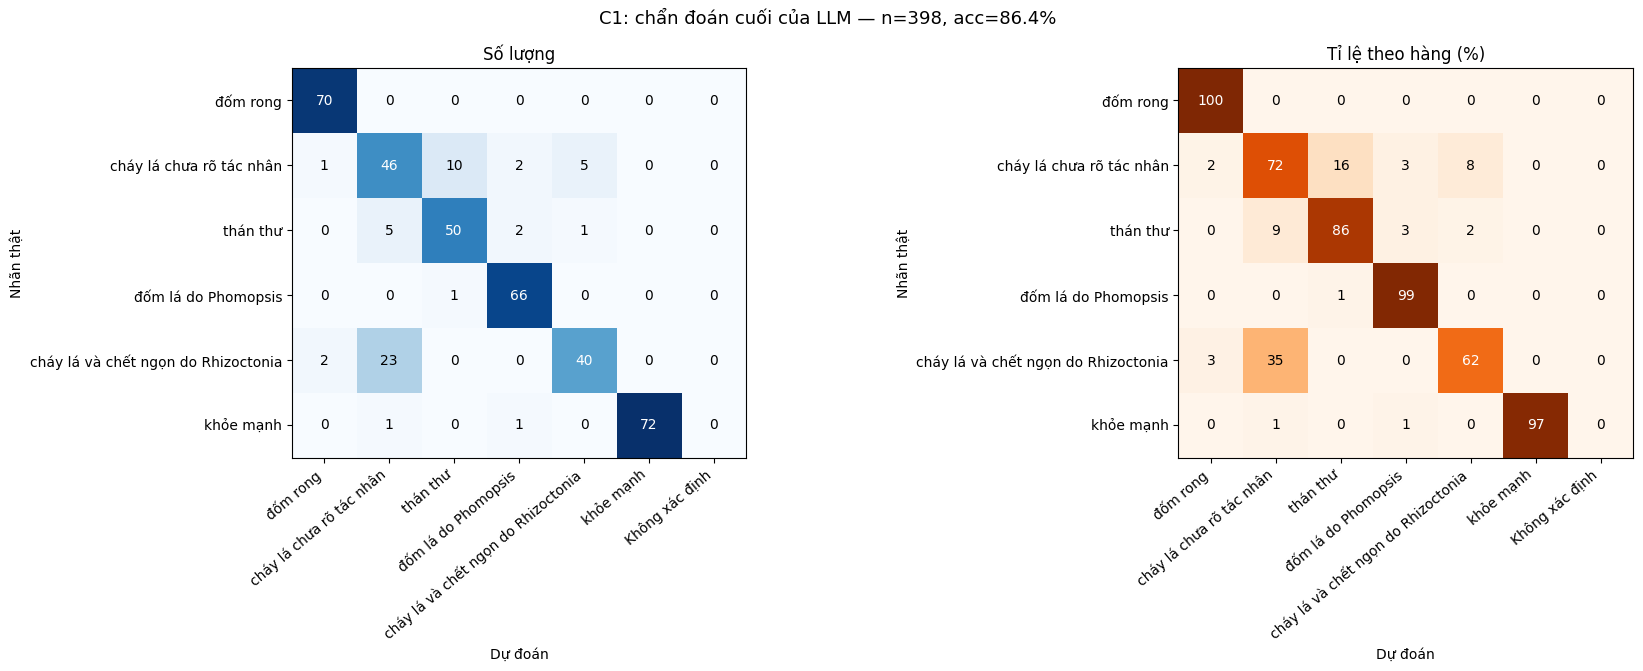


TỔNG HỢP C1
      n  Acc nhãn VLM  Acc chẩn đoán LLM  Macro-F1 LLM  LLM trùng nhãn VLM  LLM sửa đúng  LLM làm hỏng  Đúng định dạng
C1  398         0.894              0.864         0.857               0.917             9            21             1.0

Theo việc question có nêu sẵn tên bệnh hay không:
                   n  acc_vlm  acc_llm
q_names_disease                       
False            388    0.892    0.861
True              10    1.000    1.000


In [12]:
LABELS = CLASSES + [UNKNOWN]

def report(gt, pred, title, heatmap=False):
    gt, pred = pd.Series(list(gt)), pd.Series(list(pred))
    n, k = len(gt), int((gt == pred).sum())
    lo, hi = wilson_ci(k, n)
    per = []
    for c in CLASSES:
        tp = int(((gt == c) & (pred == c)).sum()); fp = int(((gt != c) & (pred == c)).sum()); fn = int(((gt == c) & (pred != c)).sum())
        p = tp / (tp + fp) if tp + fp else 0.0
        r = tp / (tp + fn) if tp + fn else 0.0
        per.append(dict(lớp=SHORT[c], precision=p, recall=r, f1=2 * p * r / (p + r) if p + r else 0.0, support=tp + fn, n_pred=tp + fp))
    per = pd.DataFrame(per)
    print(f"\n{'=' * 70}\n[{title}] n={n}\nAccuracy: {k}/{n} = {k / n:.2%}  (Wilson 95%: {lo:.1%} – {hi:.1%}) | Macro-F1: {per['f1'].mean():.3f}"
          f" | không ánh xạ được: {(pred == UNKNOWN).mean():.1%}")
    print(per.round(3).to_string(index=False))
    cm = pd.crosstab(gt, pred).reindex(index=CLASSES, columns=LABELS, fill_value=0)
    pairs = sorted([(SHORT[g], SHORT[p], int(cm.loc[g, p])) for g in CLASSES for p in LABELS if g != p and cm.loc[g, p] > 0], key=lambda x: -x[2])
    print("Nhầm nhiều nhất (thật -> đoán):", "; ".join(f"{g}->{p}: {v}" for g, p, v in pairs[:6]))
    if heatmap:
        cmn = cm.div(cm.sum(axis=1).replace(0, 1), axis=0) * 100
        fig, axes = plt.subplots(1, 2, figsize=(18, 6.8))
        for ax, mat, ttl, cmap, fmt in [(axes[0], cm, "Số lượng", "Blues", "{:d}"), (axes[1], cmn, "Tỉ lệ theo hàng (%)", "Oranges", "{:.0f}")]:
            ax.imshow(mat.values, cmap=cmap, vmin=0)
            ax.set_xticks(range(len(LABELS))); ax.set_xticklabels([SHORT[c] for c in LABELS], rotation=40, ha="right")
            ax.set_yticks(range(len(CLASSES))); ax.set_yticklabels([SHORT[c] for c in CLASSES])
            vmax = mat.values.max() or 1
            for yi in range(mat.shape[0]):
                for xi in range(mat.shape[1]):
                    v = mat.values[yi, xi]
                    ax.text(xi, yi, fmt.format(int(v) if fmt == "{:d}" else v), ha="center", va="center",
                            color="white" if v > vmax / 2 else "black", fontsize=10)
            ax.set_xlabel("Dự đoán"); ax.set_ylabel("Nhãn thật"); ax.set_title(ttl)
        fig.suptitle(f"{title} — n={n}, acc={k / n:.1%}", fontsize=13)
        plt.tight_layout()
        plt.savefig(f"{OUT_DIR}/confusion_{title.replace(' ', '_').replace(':', '')}.png", dpi=150)
        plt.show()
    return dict(acc=k / n, macro_f1=per["f1"].mean())

recs = []
for s_ in samples:
    a_ = answers_diag.get(s_["image"])
    if a_ is None:
        continue
    diag, ok = parse_diagnosis(a_["answer"])
    recs.append(dict(image=s_["image"], gt=s_["gt"], question=s_["question"],
                     vlm_label=vlm_out["label"][s_["image"]]["label"],
                     llm_pred=map_to_class(diag), n_cls_in_diag=n_distinct_classes(diag), parse_ok=ok, answer=a_["answer"]))
df = pd.DataFrame(recs)
df.to_csv(f"{OUT_DIR}/eval_c1.csv", index=False)

v = report(df["gt"], df["vlm_label"], "C1: nhãn của VLM")
l = report(df["gt"], df["llm_pred"], "C1: chẩn đoán cuối của LLM", heatmap=True)
fixed = int(((df["vlm_label"] != df["gt"]) & (df["llm_pred"] == df["gt"])).sum())     # LLM sửa nhãn sai thành đúng
broke = int(((df["vlm_label"] == df["gt"]) & (df["llm_pred"] != df["gt"])).sum())     # LLM làm hỏng nhãn đúng

print("\n" + "=" * 70 + "\nTỔNG HỢP C1\n" + "=" * 70)
summary = pd.DataFrame([{"n": len(df), "Acc nhãn VLM": v["acc"], "Acc chẩn đoán LLM": l["acc"], "Macro-F1 LLM": l["macro_f1"],
                         "LLM trùng nhãn VLM": (df["llm_pred"] == df["vlm_label"]).mean(), "LLM sửa đúng": fixed, "LLM làm hỏng": broke,
                         "Đúng định dạng": df["parse_ok"].mean()}], index=["C1"])
print(summary.round(3).to_string())
summary.to_csv(f"{OUT_DIR}/summary_c1.csv")

# Kiểm tra ảnh hưởng của question: kết quả có khác nhau khi question đã nêu sẵn tên bệnh không?
df["q_names_disease"] = df["question"].map(lambda q: map_to_class(q) != UNKNOWN)
tmp = df.assign(llm_ok=df["llm_pred"] == df["gt"], vlm_ok=df["vlm_label"] == df["gt"])
print("\nTheo việc question có nêu sẵn tên bệnh hay không:")
print(tmp.groupby("q_names_disease").agg(n=("image", "size"), acc_vlm=("vlm_ok", "mean"), acc_llm=("llm_ok", "mean")).round(3).to_string())

In [13]:
# ---- Kiểm định McNemar (chính xác): LLM có thật sự làm thay đổi accuracy so với nhãn VLM không? ----
from scipy.stats import binomtest
b, c = broke, fixed                         # b: VLM đúng -> LLM sai ; c: VLM sai -> LLM đúng
if b + c > 0:
    p = binomtest(min(b, c), b + c, 0.5).pvalue
    print(f"LLM làm hỏng {b} | LLM sửa đúng {c} | McNemar exact p = {p:.4f} -> "
          + ("khác biệt có ý nghĩa (p<0.05)" if p < 0.05 else "CHƯA đủ bằng chứng khác biệt (p>=0.05)"))
print(f"LLM nêu >1 bệnh trong dòng chẩn đoán: {(df['n_cls_in_diag'] > 1).sum()}/{len(df)} ảnh")
print(f"Tỉ lệ VLM đúng nhưng LLM đổi sang nhãn khác (ảo giác chẩn đoán so với đầu vào): {broke}/{int((df['vlm_label'] == df['gt']).sum())} = {broke / max(int((df['vlm_label'] == df['gt']).sum()), 1):.1%}")

LLM làm hỏng 21 | LLM sửa đúng 9 | McNemar exact p = 0.0428 -> khác biệt có ý nghĩa (p<0.05)
LLM nêu >1 bệnh trong dòng chẩn đoán: 0/398 ảnh
Tỉ lệ VLM đúng nhưng LLM đổi sang nhãn khác (ảo giác chẩn đoán so với đầu vào): 21/356 = 5.9%


## 7. Đánh giá ẢO GIÁC của LLM (cấu hình 1)

**Ảo giác** = LLM nêu thông tin sai hoặc không có căn cứ (tên bệnh, tác nhân, triệu chứng, thuốc/hoạt chất, liều lượng, thời gian cách ly) — đúng định nghĩa trong báo cáo (mục 3.9). Vì C1 **không có tài liệu**, mọi chi tiết LLM nêu ra đều từ "trí nhớ"; đây là mốc so sánh để thấy RAG ở C2–C4 cải thiện bao nhiêu.

| Mức | Cần gì | Đo gì |
|---|---|---|
| **Mức 1** (tự động, không cần đáp án) | chỉ câu tư vấn | LLM có đưa tên thuốc/liều lượng/thời gian cách ly không (rủi ro cao); có lệch ngôn ngữ không; có mâu thuẫn với nhãn VLM không |
| **Mức 2** (cần `disease_reference.json`) | tri thức chuẩn từng bệnh | tách câu tư vấn thành các mệnh đề → mỗi mệnh đề: `SUPPORTED` / `CONTRADICTED` / `UNSUPPORTED` → **tỉ lệ ảo giác** |

> **Lưu ý phương pháp:** giám khảo ở Mức 2 là chính Qwen2.5-7B (đang nạp sẵn) → có thiên lệch tự chấm. Notebook xuất `human_check_c1.csv` (30 câu) để bạn/chuyên gia chấm tay đối chiếu — đúng yêu cầu "Human Evaluation" trong báo cáo. `UNSUPPORTED` chưa chắc là sai (có thể đúng nhưng tài liệu không nêu) nên luôn báo cáo riêng `CONTRADICTED` và tỉ lệ ảo giác "chặt" (CONTRADICTED + UNSUPPORTED).

In [14]:
# ====== 7.1 Tri thức chuẩn (ground truth) ======
REF_FIELDS = ["ten_benh", "tac_nhan", "trieu_chung", "phong_ngua", "xu_ly", "hoat_chat_duoc_phep", "nguon"]

def write_reference_template(path):
    tpl = {}
    for k in ORDER:
        tpl[k] = {f: ("" if f in ("ten_benh", "tac_nhan", "nguon") else []) for f in REF_FIELDS}
        tpl[k]["ten_benh"] = DISEASE_MAP[k]["display"]
    with open(path, "w", encoding="utf-8") as f:
        json.dump(tpl, f, ensure_ascii=False, indent=2)

template_path = f"{OUT_DIR}/disease_reference_TEMPLATE.json"
write_reference_template(template_path)
print("Đã tạo file mẫu để điền:", template_path)

LBL = dict(ten_benh="Tên bệnh", tac_nhan="Tác nhân", trieu_chung="Triệu chứng", phong_ngua="Phòng ngừa",
           xu_ly="Xử lý / phác đồ", hoat_chat_duoc_phep="Hoạt chất được phép", nguon="Nguồn")

def reference_text(r):
    parts, content_len = [], 0
    for f in REF_FIELDS:
        v = r.get(f)
        if not v:
            continue
        txt = "; ".join(map(str, v)) if isinstance(v, list) else str(v)
        parts.append(f"{LBL[f]}: {txt}")
        if f not in ("ten_benh", "nguon"):
            content_len += len(txt)
    return "\n".join(parts), content_len

reference = {}
if REFERENCE_PATH and os.path.isfile(REFERENCE_PATH):
    with open(REFERENCE_PATH, "r", encoding="utf-8") as f:
        raw_ref = json.load(f)
    for k in ORDER:
        txt, n_content = reference_text(raw_ref.get(k, {}))
        if n_content >= 40:
            reference[k] = txt
        else:
            print(f"  ! Lớp {k}: tri thức chuẩn trống/quá ngắn -> bỏ qua khi chấm Mức 2")
    print(f"Đã nạp tri thức chuẩn cho {len(reference)}/6 lớp.")
else:
    print("CHƯA có REFERENCE_PATH -> chỉ chạy Mức 1. Điền file mẫu ở trên (từ tài liệu BVTV / chuyên gia), upload lên Kaggle, rồi đặt REFERENCE_PATH.")
HAS_REF = len(reference) > 0

Đã tạo file mẫu để điền: /kaggle/working/config1/disease_reference_TEMPLATE.json
Đã nạp tri thức chuẩn cho 6/6 lớp.


In [15]:
# ====== 7.2 MỨC 1: chỉ số tự động trên câu tư vấn đầy đủ ======
ACTIVE_INGREDIENTS = ["mancozeb", "azoxystrobin", "difenoconazole", "hexaconazole", "propiconazole", "tebuconazole",
    "carbendazim", "thiophanate", "metalaxyl", "fosetyl", "phosphonate", "chlorothalonil", "captan", "validamycin",
    "pyraclostrobin", "trifloxystrobin", "kasugamycin", "zineb", "propineb", "thiram", "benomyl", "iprodione",
    "oxychloride", "oxyclorua", "bordeaux", "boóc đô", "boóc-đô", "gốc đồng", "copper", "trichoderma", "bacillus", "chitosan"]
RE_CHEM_SUFFIX = re.compile(r"\b[a-z]*(?:conazole|strobin|zeb|mycin|thalonil|azole|phosph\w*|oxychlor\w*)\b", re.I)
RE_DOSE = re.compile(r"\d+(?:[.,]\d+)?\s*(?:-\s*\d+(?:[.,]\d+)?\s*)?(?:g|gam|gram|kg|ml|cc|lít|l)\b\s*(?:/|trên|cho|mỗi|pha)\s*(?:\d+\s*)?(?:lít|l|bình|ha|cây|sào|công|m2|m²)", re.I)
RE_PHI = re.compile(r"cách ly|thời gian chờ|\d+\s*(?:-\s*\d+\s*)?ngày", re.I)
RE_CJK = re.compile(r"[\u4e00-\u9fff\u3040-\u30ff\uac00-\ud7af]")

def chem_hits(text):
    low = unicodedata.normalize("NFC", text or "").lower()
    hits = {a for a in ACTIVE_INGREDIENTS if a in low}
    hits |= {m.group(0).lower() for m in RE_CHEM_SUFFIX.finditer(low)}
    return sorted(hits)

def is_risk_text(text):
    return bool(chem_hits(text) or RE_DOSE.search(text or "") or RE_PHI.search(text or ""))

rows = []
for s_ in samples_adv:
    a_ = answers_adv.get(s_["image"])
    if a_ is None:
        continue
    diag, ok = parse_diagnosis(a_["answer"])
    pred = map_to_class(diag)
    chems = chem_hits(a_["answer"])
    rows.append(dict(image=s_["image"], gt=s_["gt"], vlm_label=vlm_out["label"][s_["image"]]["label"], llm_pred=pred,
                     dx_correct=(pred == s_["gt"]), llm_differs_from_vlm=(pred != vlm_out["label"][s_["image"]]["label"]),
                     n_words=len(a_["answer"].split()), n_chem=len(chems), chems=", ".join(chems),
                     has_dose=bool(RE_DOSE.search(a_["answer"])), has_phi_or_interval=bool(RE_PHI.search(a_["answer"])),
                     lang_drift=bool(RE_CJK.search(a_["answer"])), answer=a_["answer"]))
adv = pd.DataFrame(rows)
adv.to_csv(f"{OUT_DIR}/advice_level1_c1.csv", index=False)

L1 = {
    "n_answers": len(adv),
    "acc_chẩn_đoán (tập con)": adv["dx_correct"].mean(),
    "% nêu tên thuốc/hoạt chất": (adv["n_chem"] > 0).mean(),
    "TB số hoạt chất/câu": adv["n_chem"].mean(),
    "% nêu liều lượng": adv["has_dose"].mean(),
    "% nêu thời gian (cách ly/khoảng cách)": adv["has_phi_or_interval"].mean(),
    "% lệch ngôn ngữ (CJK)": adv["lang_drift"].mean(),
    "% LLM đổi nhãn so với VLM": adv["llm_differs_from_vlm"].mean(),
    "TB số từ": adv["n_words"].mean(),
}
print("MỨC 1 — chỉ số tự động (C1, không RAG):")
for k, v in L1.items():
    print(f"  {k:42s}: {v:.1%}" if isinstance(v, float) and v <= 1.0 and 'TB' not in k else f"  {k:42s}: {v:.2f}" if isinstance(v, float) else f"  {k:42s}: {v}")
print("\nHoạt chất LLM hay nêu nhất:")
print(pd.Series([c for x in adv["chems"] for c in x.split(", ") if c]).value_counts().head(10).to_string())
print("\nLưu ý: ở C1 không có tài liệu, mọi tên thuốc/liều lượng đều là rủi ro cần đối chiếu với tri thức chuẩn (Mức 2).")

MỨC 1 — chỉ số tự động (C1, không RAG):
  n_answers                                 : 120
  acc_chẩn_đoán (tập con)                   : 86.7%
  % nêu tên thuốc/hoạt chất                 : 29.2%
  TB số hoạt chất/câu                       : 0.56
  % nêu liều lượng                          : 0.0%
  % nêu thời gian (cách ly/khoảng cách)     : 5.0%
  % lệch ngôn ngữ (CJK)                     : 0.0%
  % LLM đổi nhãn so với VLM                 : 7.5%
  TB số từ                                  : 183.05

Hoạt chất LLM hay nêu nhất:
thiophanate     32
mancozeb        18
carbendazim     13
bacillus         1
metalaxyl        1
streptomycin     1
copper           1

Lưu ý: ở C1 không có tài liệu, mọi tên thuốc/liều lượng đều là rủi ro cần đối chiếu với tri thức chuẩn (Mức 2).


In [16]:
# ====== 7.3 MỨC 2: tách mệnh đề -> kiểm chứng với tri thức chuẩn ======
def chat_prompt(system, user):
    return llm_tok.apply_chat_template([{"role": "system", "content": system}, {"role": "user", "content": user}],
                                       tokenize=False, add_generation_prompt=True)

EXTRACT_SYS = "Bạn là trợ lý tách ý. Chỉ trả về JSON hợp lệ, không giải thích."
VERIFY_SYS  = ("Bạn là giám khảo kiểm chứng thông tin bệnh cây trồng. Chỉ so sánh với TÀI LIỆU THAM CHIẾU được cung cấp, "
               "KHÔNG dùng kiến thức riêng. Chỉ trả về JSON hợp lệ, không giải thích.")

def body_of(answer):
    # bỏ dòng 'Chẩn đoán:' (đã đo bằng accuracy); chỉ kiểm chứng phần tư vấn
    lines = [l for l in (answer or "").split("\n")]
    if lines and DIAG_RE.search(lines[0]):
        lines = lines[1:]
    return "\n".join(lines).strip()

def extract_prompt(body):
    return chat_prompt(EXTRACT_SYS,
        "Tách đoạn tư vấn sau thành các MỆNH ĐỀ THÔNG TIN độc lập, mỗi mệnh đề một ý, tự đủ nghĩa (nêu rõ chủ thể, không dùng 'nó', 'chúng'). "
        "Chỉ lấy mệnh đề về: tác nhân, triệu chứng, nguyên nhân, mức độ, phòng ngừa, cách xử lý, tên thuốc/hoạt chất, liều lượng, thời gian. "
        "Bỏ câu xã giao và câu chỉ thể hiện sự không chắc chắn.\n\n"
        f"Đoạn tư vấn:\n{body}\n\nTrả về đúng định dạng: {{\"claims\": [\"...\", \"...\"]}}")

def verify_prompt(ref_txt, claims):
    lst = "\n".join(f"{i + 1}. {c}" for i, c in enumerate(claims))
    return chat_prompt(VERIFY_SYS,
        f"TÀI LIỆU THAM CHIẾU (đúng cho bệnh của lá này):\n{ref_txt}\n\nCÁC MỆNH ĐỀ CẦN KIỂM:\n{lst}\n\n"
        "Với MỖI mệnh đề chọn đúng một nhãn:\n"
        "- SUPPORTED: tài liệu nêu rõ hoặc suy ra trực tiếp.\n"
        "- CONTRADICTED: trái với tài liệu (sai thông tin, nói về bệnh khác, sai thuốc/liều/thời gian).\n"
        "- UNSUPPORTED: tài liệu không đề cập.\n"
        "Trả về đúng định dạng: {\"verdicts\": [{\"id\": 1, \"label\": \"SUPPORTED\"}, ...]}")

def parse_claims(raw, fallback_text):
    obj = extract_json(raw)
    cl = obj.get("claims") if obj else None
    if isinstance(cl, list):
        c = [str(x).strip() for x in cl if str(x).strip()]
        if c:
            return c[:MAX_CLAIMS], True
    parts = [p.strip(" -*•\t") for p in re.split(r"[\n.;]+", fallback_text or "")]
    return [p for p in parts if len(p.split()) >= 4][:MAX_CLAIMS], False

def parse_verdicts(raw, n):
    out = ["UNPARSED"] * n
    obj = extract_json(raw)
    v = obj.get("verdicts") if obj else None
    if isinstance(v, list):
        for it in v:
            try:
                i = int(it.get("id")) - 1
                lab = str(it.get("label", "")).upper().strip()
            except Exception:
                continue
            if 0 <= i < n and lab in ("SUPPORTED", "CONTRADICTED", "UNSUPPORTED"):
                out[i] = lab
    return out

def run_judge():
    path = f"{OUT_DIR}/halluc_judge_c1.jsonl"
    done = load_jsonl_dict(path) if RESUME else {}
    todo_j = [s for s in samples_adv if s["image"] in answers_adv and s["image"] not in done and KEY_OF[s["gt"]] in reference]
    print(f"[judge] đã có: {len(done)} | cần chạy: {len(todo_j)}")
    t0 = time.time()
    with open(path, "a" if RESUME else "w", encoding="utf-8") as fout:
        for i in tqdm(range(0, len(todo_j), LLM_BATCH), desc="LLM[judge]"):
            chunk = todo_j[i:i + LLM_BATCH]
            bodies = [body_of(answers_adv[s["image"]]["answer"]) for s in chunk]
            raw_a = llm_generate([extract_prompt(b) for b in bodies], 450, stop_at_newline=False)
            claims_l = [parse_claims(r, b) for r, b in zip(raw_a, bodies)]
            vprompts, idx = [], []
            for j, (s, (cl, _)) in enumerate(zip(chunk, claims_l)):
                if cl:
                    vprompts.append(verify_prompt(reference[KEY_OF[s["gt"]]], cl)); idx.append(j)
            raw_b = dict(zip(idx, llm_generate(vprompts, 40 * MAX_CLAIMS, stop_at_newline=False))) if vprompts else {}
            for j, s in enumerate(chunk):
                cl, extract_ok = claims_l[j]
                verd = parse_verdicts(raw_b.get(j, ""), len(cl)) if cl else []
                rec = dict(image=s["image"], gt=s["gt"], claims=cl, verdicts=verd, extract_ok=extract_ok)
                fout.write(json.dumps(rec, ensure_ascii=False) + "\n")
                done[s["image"]] = rec
            fout.flush()
    print(f"[judge] xong sau {(time.time() - t0) / 60:.1f} phút")
    return done

judge = run_judge() if HAS_REF else {}

[judge] đã có: 0 | cần chạy: 120


LLM[judge]:   0%|          | 0/5 [00:00<?, ?it/s]

[judge] xong sau 12.9 phút


In [17]:
# ====== 7.4 Tổng hợp tỉ lệ ảo giác ======
def halluc_rates(d):
    ok = d[d["verdict"] != "UNPARSED"]
    n = len(ok)
    if n == 0:
        return dict(n_claims=0)
    c = (ok["verdict"] == "CONTRADICTED").sum(); u = (ok["verdict"] == "UNSUPPORTED").sum()
    return dict(n_claims=n, supported=1 - (c + u) / n, contradicted=c / n, unsupported=u / n, halluc_strict=(c + u) / n)

def boot_ci(d, B=2000, seed=0):
    # bootstrap THEO ẢNH (các mệnh đề cùng 1 câu không độc lập)
    ok = d[d["verdict"] != "UNPARSED"]
    per = ok.groupby("image").agg(total=("verdict", "size"), bad=("verdict", lambda v: int((v != "SUPPORTED").sum())))
    if len(per) < 2:
        return (np.nan, np.nan)
    rng = np.random.default_rng(seed); t, b = per["total"].values, per["bad"].values
    vals = []
    for _ in range(B):
        ix = rng.integers(0, len(per), len(per))
        vals.append(b[ix].sum() / max(t[ix].sum(), 1))
    return tuple(np.percentile(vals, [2.5, 97.5]))

if HAS_REF and judge:
    crow = []
    dxmap = dict(zip(adv["image"], adv["dx_correct"]))
    for img, r in judge.items():
        for cl, vd in zip(r["claims"], r["verdicts"]):
            crow.append(dict(image=img, gt=r["gt"], claim=cl, verdict=vd, risk=is_risk_text(cl), dx_correct=dxmap.get(img, False)))
    claims_df = pd.DataFrame(crow)
    claims_df.to_csv(f"{OUT_DIR}/halluc_claims_c1.csv", index=False)

    n_img = claims_df["image"].nunique()
    print(f"Đã chấm {n_img} câu tư vấn | {len(claims_df)} mệnh đề | mệnh đề không đọc được nhãn: {(claims_df['verdict'] == 'UNPARSED').mean():.1%}"
          f" | câu phải dùng tách câu dự phòng: {sum(not r['extract_ok'] for r in judge.values())}")

    slices = {"TẤT CẢ mệnh đề": claims_df,
              "Chỉ khi chẩn đoán ĐÚNG (ảo giác thuần kiến thức)": claims_df[claims_df["dx_correct"]],
              "Chỉ mệnh đề RỦI RO (thuốc/liều/thời gian)": claims_df[claims_df["risk"]]}
    out_rows = []
    for name, d in slices.items():
        r = halluc_rates(d); lo, hi = boot_ci(d)
        out_rows.append(dict(nhóm=name, **r, ci_lo=lo, ci_hi=hi))
    hall = pd.DataFrame(out_rows).set_index("nhóm")
    print("\nTỈ LỆ ẢO GIÁC C1 (halluc_strict = CONTRADICTED + UNSUPPORTED; ci = bootstrap 95% theo ảnh):")
    print(hall.round(3).to_string())

    per_img = claims_df[claims_df["verdict"] != "UNPARSED"].groupby("image")["verdict"].apply(lambda v: (v == "CONTRADICTED").any())
    print(f"\n% câu tư vấn có ÍT NHẤT 1 mệnh đề mâu thuẫn tài liệu: {per_img.mean():.1%}")
    print("\nTheo lớp bệnh (halluc_strict):")
    bycls = {SHORT[c]: halluc_rates(claims_df[claims_df['gt'] == c]) for c in CLASSES if (claims_df['gt'] == c).any()}
    print(pd.DataFrame(bycls).T.round(3).to_string())
    hall.to_csv(f"{OUT_DIR}/summary_halluc_c1.csv")

    # Mẫu để chuyên gia chấm tay (kiểm tra độ tin cậy của giám khảo tự động)
    hs = stratified_sample([s for s in samples_adv if s["image"] in judge], 30, seed=SEED)
    hrows = []
    for s_ in hs:
        r = judge[s_["image"]]
        hrows.append(dict(image=s_["image"], bệnh_thật=SHORT[s_["gt"]], tư_vấn=answers_adv[s_["image"]]["answer"],
                          mệnh_đề_và_nhãn_tự_động=" || ".join(f"[{v}] {c}" for c, v in zip(r["claims"], r["verdicts"])),
                          điểm_chất_lượng_1_5="", số_mệnh_đề_ảo_giác="", ghi_chú=""))
    pd.DataFrame(hrows).to_csv(f"{OUT_DIR}/human_check_c1.csv", index=False)
    print(f"\nĐã xuất {OUT_DIR}/human_check_c1.csv (30 câu để chấm tay).")
else:
    print("Bỏ qua Mức 2 vì chưa có tri thức chuẩn. Kết quả Mức 1 ở trên đã lưu trong advice_level1_c1.csv.")

Đã chấm 120 câu tư vấn | 1299 mệnh đề | mệnh đề không đọc được nhãn: 11.0% | câu phải dùng tách câu dự phòng: 0

TỈ LỆ ẢO GIÁC C1 (halluc_strict = CONTRADICTED + UNSUPPORTED; ci = bootstrap 95% theo ảnh):
                                                  n_claims  supported  contradicted  unsupported  halluc_strict  ci_lo  ci_hi
nhóm                                                                                                                         
TẤT CẢ mệnh đề                                        1156      0.604         0.044        0.352          0.396  0.354  0.436
Chỉ khi chẩn đoán ĐÚNG (ảo giác thuần kiến thức)       972      0.630         0.039        0.331          0.370  0.328  0.410
Chỉ mệnh đề RỦI RO (thuốc/liều/thời gian)               48      0.521         0.125        0.354          0.479  0.352  0.619

% câu tư vấn có ÍT NHẤT 1 mệnh đề mâu thuẫn tài liệu: 31.2%

Theo lớp bệnh (halluc_strict):
                                     n_claims  supported  contradicted  

In [18]:
# ====== Lưu thông tin lần chạy (để tái lập) ======
import transformers, platform
meta = dict(vlm=VLM_BASE_MODEL, adapter=VLM_ADAPTER_PATH, llm=LLM_NAME, llm_quant="nf4-4bit", transformers=transformers.__version__,
            torch=torch.__version__, python=platform.python_version(), seed=SEED, n_images=len(samples), n_advice=len(samples_adv),
            vlm_label_prompt=VLM_LABEL_PROMPT, vlm_desc_prompt=VLM_DESC_PROMPT, system_prompt=SYSTEM_PROMPT,
            has_reference=HAS_REF, judge="Qwen2.5-7B-Instruct (cùng LLM sinh câu trả lời)")
with open(f"{OUT_DIR}/run_meta_c1.json", "w", encoding="utf-8") as f:
    json.dump(meta, f, ensure_ascii=False, indent=2)
print(sorted(os.listdir(OUT_DIR)))

['advice_level1_c1.csv', 'answers_c1.jsonl', 'answers_c1_diag.jsonl', 'confusion_C1_chẩn_đoán_cuối_của_LLM.png', 'disease_reference_TEMPLATE.json', 'eval_c1.csv', 'halluc_claims_c1.csv', 'halluc_judge_c1.jsonl', 'human_check_c1.csv', 'run_meta_c1.json', 'summary_c1.csv', 'summary_halluc_c1.csv', 'vlm_c1_desc.jsonl', 'vlm_c1_label.jsonl']


## Demo

In [19]:
from transformers import (Qwen2_5_VLForConditionalGeneration, AutoProcessor,
                          AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig)
from qwen_vl_utils import process_vision_info
from peft import PeftModel

# ---- VLM ----
if "processor" not in globals():
    processor = AutoProcessor.from_pretrained(VLM_BASE_MODEL, min_pixels=VLM_MIN_PIXELS, max_pixels=VLM_MAX_PIXELS)
    processor.tokenizer.padding_side = "left"
if "vlm_model" not in globals():
    vlm_model = Qwen2_5_VLForConditionalGeneration.from_pretrained(VLM_BASE_MODEL, dtype=VLM_DTYPE, device_map={"": 0})
    vlm_model = PeftModel.from_pretrained(vlm_model, VLM_ADAPTER_PATH).merge_and_unload()
    vlm_model.eval()

# ---- LLM (thường còn trong bộ nhớ vì cell 16 chỉ xóa VLM) ----
if "llm" not in globals():
    llm_tok = AutoTokenizer.from_pretrained(LLM_NAME)
    llm_tok.padding_side = "left"
    bnb = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4",
                             bnb_4bit_compute_dtype=LLM_DTYPE, bnb_4bit_use_double_quant=True)
    llm = AutoModelForCausalLM.from_pretrained(LLM_NAME, quantization_config=bnb, dtype=LLM_DTYPE, device_map={"": 0})
    llm.eval()

print("VRAM:", round(torch.cuda.memory_allocated() / 2**30, 2), "GiB")


Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

VRAM: 12.18 GiB


## test live

In [20]:
def diagnose(img_path, question):
    q = (question or "").strip() or NEUTRAL_QUESTION
    raw_l = _vlm_generate([dict(path=img_path, prompt=VLM_LABEL_PROMPT)], VLM_MAX_PIXELS, VLM_LABEL_MAX_NEW_TOKENS)[0].strip()
    raw_d = _vlm_generate([dict(path=img_path, prompt=VLM_DESC_PROMPT)],  VLM_MAX_PIXELS, VLM_DESC_MAX_NEW_TOKENS)[0].strip()
    label_rec = dict(label=map_to_class(raw_l), vlm_raw=raw_l)
    desc_rec  = dict(**post_desc(raw_d), vlm_raw=raw_d)
    ans = _llm_generate([build_prompt(label_rec, desc_rec, q)], LLM_MAX_NEW_TOKENS, False)[0]
    return SHORT[label_rec["label"]], (desc_rec["vlm_json"] or {"raw": raw_d}), \
           ans + "\n\n⚠️ Kết quả mang tính tham khảo, hãy hỏi cán bộ bảo vệ thực vật trước khi dùng thuốc."

# thử 1 ảnh (chạy được cả ở chế độ Save & Commit)
_lbl, _desc, _ans = diagnose(samples[0]["path"], "")
print("GT:", SHORT[samples[0]["gt"]], "| Nhãn VLM:", _lbl)
print(_desc)
print(_ans[:600])

# Gradio chỉ có ý nghĩa khi chạy tương tác. Ở Save & Commit (Batch) bỏ qua để không treo / không lỗi do không có internet.
IS_INTERACTIVE = os.environ.get("KAGGLE_KERNEL_RUN_TYPE", "Interactive") == "Interactive"
if IS_INTERACTIVE:
    import gradio as gr
    demo = gr.Interface(
        fn=diagnose,
        inputs=[gr.Image(type="filepath", label="Ảnh lá sầu riêng"), gr.Textbox(label="Câu hỏi (có thể để trống)")],
        outputs=[gr.Textbox(label="Nhãn VLM"), gr.JSON(label="Mô tả vết bệnh (VLM)"), gr.Textbox(label="Chẩn đoán + tư vấn (LLM)")],
        title="Chẩn đoán bệnh lá sầu riêng, Cấu hình 1 (VLM + LLM, không RAG)",
    )
    try:
        demo.launch(share=True, prevent_thread_lock=True)   # không chặn kernel; link công khai chỉ sống khi phiên còn chạy
    except Exception as e:
        print("Không mở được Gradio:", type(e).__name__, e)
else:
    print("Chế độ Save & Commit (Batch) -> bỏ qua Gradio.")


GT: đốm lá do Phomopsis | Nhãn VLM: đốm lá do Phomopsis
{'lesion_color': 'Nâu nhạt', 'lesion_shape': 'Hình tròn hoặc bầu dục', 'distribution': 'Rải rác trên phiến lá', 'severity': 'Trung bình'}
Chẩn đoán: Đốm lá do Phomopsis

Lý do: Các vết bệnh có màu nâu nhạt, hình tròn hoặc bầu dục, rải rác trên phiến lá và có mức độ nghiêm trọng trung bình, đều phù hợp với triệu chứng của bệnh đốm lá do Phomopsis. Đây là bệnh phổ biến trên cây sầu riêng, gây hại chủ yếu vào mùa mưa.

Mức độ nghiêm trọng: Bệnh đốm lá do Phomopsis thường không gây hại nặng nề đến cây trồng nếu được kiểm soát kịp thời. Tuy nhiên, nó có thể làm giảm năng suất và chất lượng quả nếu bệnh diễn biến nặng.

Phác đồ xử lý: 
1. Thu gom và tiêu hủy các lá bị bệnh.
2. Sử dụng thuốc trừ nấm như thiophanate-methyl hoặc mancozeb
Chế độ Save & Commit (Batch) -> bỏ qua Gradio.


## test trên thư mục

In [21]:
EXT_DIR = "/kaggle/input/datasets/hhaaad/testdata01/dataTest"   # <- đổi lại nếu cần
from collections import Counter

ext = []
if os.path.isdir(EXT_DIR):
    paths = sorted(p for p in glob.glob(EXT_DIR + "/**/*", recursive=True) if p.lower().endswith(IMAGE_EXTS))
    ext = [dict(image=os.path.relpath(p, EXT_DIR), path=p) for p in paths]
else:
    print(f"Không thấy {EXT_DIR} (chưa gắn dataset vào notebook?) -> bỏ qua phần test ảnh ngoài.")

if ext:
    sz = Counter()
    for p in paths:
        with Image.open(p) as im:
            sz[im.size] += 1
    print(len(ext), "ảnh | kích thước phổ biến:", dict(sz.most_common(5)))

    # ---------- PHA 1: VLM (nhãn + mô tả) ----------
    if "vlm_model" not in globals() or "processor" not in globals():
        from transformers import Qwen2_5_VLForConditionalGeneration, AutoProcessor
        from qwen_vl_utils import process_vision_info
        from peft import PeftModel
        processor = AutoProcessor.from_pretrained(VLM_BASE_MODEL, min_pixels=VLM_MIN_PIXELS, max_pixels=VLM_MAX_PIXELS)
        processor.tokenizer.padding_side = "left"
        vlm_model = Qwen2_5_VLForConditionalGeneration.from_pretrained(VLM_BASE_MODEL, dtype=VLM_DTYPE, device_map={"": 0})
        vlm_model = PeftModel.from_pretrained(vlm_model, VLM_ADAPTER_PATH).merge_and_unload()
        vlm_model.eval()

    raw_out = {"label": {}, "desc": {}}
    for kind, prompt, mx in (("label", VLM_LABEL_PROMPT, VLM_LABEL_MAX_NEW_TOKENS), ("desc", VLM_DESC_PROMPT, VLM_DESC_MAX_NEW_TOKENS)):
        for i in tqdm(range(0, len(ext), VLM_BATCH), desc=f"VLM ext [{kind}]"):
            chunk = ext[i:i + VLM_BATCH]
            outs = run_vlm_items([dict(path=s["path"], prompt=prompt) for s in chunk], mx)
            for s, (raw, px) in zip(chunk, outs):
                raw_out[kind][s["image"]] = raw
    raw_l = [raw_out["label"][s["image"]] for s in ext]
    raw_d = [raw_out["desc"][s["image"]] for s in ext]

    # 1) LƯU kết quả VLM ngay
    pd.DataFrame(dict(image=[s["image"] for s in ext], raw_l=raw_l, raw_d=raw_d)).to_csv(f"{OUT_DIR}/external_vlm_raw.csv", index=False)
    print("Đã lưu", f"{OUT_DIR}/external_vlm_raw.csv")

    # 2) Giải phóng VLM (cell Gradio ở trên sẽ không dùng được nữa sau bước này)
    sys.last_traceback = sys.last_value = sys.last_type = None
    for n in ("vlm_model", "processor"):
        globals().pop(n, None)
    gc.collect(); free_cuda()
    used = torch.cuda.memory_allocated() / 2**30
    print(f"VRAM đang dùng: {used:.2f} GiB (kỳ vọng ~5,2)")
    if used >= 8:
        print("CẢNH BÁO: VLM có thể vẫn còn trong GPU; llm_generate sẽ tự chia nhỏ batch khi OOM.")

    # ---------- PHA 2: LLM ----------
    recs_ext = []
    for s, rl, rd in zip(ext, raw_l, raw_d):
        label_rec = dict(label=map_to_class(rl), vlm_raw=rl)
        desc_rec = dict(**post_desc(rd), vlm_raw=rd)
        recs_ext.append(dict(image=s["image"], vlm_label=label_rec["label"], vlm_raw_label=rl, vlm_raw_desc=rd,
                             prompt=build_prompt(label_rec, desc_rec, NEUTRAL_QUESTION)))
    prompts = [r["prompt"] for r in recs_ext]
    answers = []
    for i in tqdm(range(0, len(prompts), 4), desc="LLM ext"):
        answers += llm_generate(prompts[i:i + 4], LLM_MAX_NEW_TOKENS, False)
    print("câu lỗi OOM:", sum(a.startswith("[ERROR]") for a in answers), "/", len(answers))

    ext_df = pd.DataFrame(recs_ext).drop(columns="prompt").assign(answer=answers)
    ext_df["llm_pred"] = ext_df["answer"].map(lambda a: map_to_class(parse_diagnosis(a)[0]))
    ext_df.to_csv(f"{OUT_DIR}/external_c1.csv", index=False)
    print(ext_df["llm_pred"].map(SHORT).value_counts().to_string())


40 ảnh | kích thước phổ biến: {(800, 600): 9, (1000, 563): 6, (2500, 1406): 3, (1200, 628): 2, (600, 800): 2}


VLM ext [label]:   0%|          | 0/5 [00:00<?, ?it/s]

VLM ext [desc]:   0%|          | 0/5 [00:00<?, ?it/s]

Đã lưu /kaggle/working/config1/external_vlm_raw.csv
VRAM đang dùng: 5.19 GiB (kỳ vọng ~5,2)


LLM ext:   0%|          | 0/10 [00:00<?, ?it/s]

câu lỗi OOM: 0 / 40
llm_pred
đốm rong                               17
thán thư                               14
cháy lá chưa rõ tác nhân                4
đốm lá do Phomopsis                     3
cháy lá và chết ngọn do Rhizoctonia     2


In [22]:
OUT = OUT_DIR
RHIZ   = "Bệnh cháy lá, chết ngọn (Rhizoctonia sp.)"
BLIGHT = "Bệnh cháy lá, chưa xác định tác nhân (Leaf_Blight)"
FIELDS = VLM_JSON_FIELDS

df_c1 = pd.read_csv(f"{OUT}/eval_c1.csv")      # không ghi đè biến df của mục 6
desc = load_jsonl_dict(f"{OUT}/vlm_c1_desc.jsonl")

bad  = df_c1[(df_c1.gt == RHIZ) & (df_c1.llm_pred == BLIGHT)]   # Rhizoctonia bị LLM đổi sang Blight
good = df_c1[(df_c1.gt == RHIZ) & (df_c1.llm_pred == RHIZ)]     # đối chứng: giữ đúng
print(f"bad={len(bad)} (VLM đã đúng sẵn: {(bad.vlm_label == RHIZ).sum()}) | good={len(good)}")

if len(bad) == 0 or len(good) == 0:
    print("Không đủ mẫu ở một trong hai nhóm -> bỏ qua phân tích chi tiết.")
else:
    def words(d):
        c = Counter()
        for i in d.image:
            j = desc.get(i, {}).get("vlm_json") or {}
            c.update(set(" ".join(str(j.get(f, "")) for f in FIELDS).lower().replace(",", " ").split()))
        return c
    wb, wg = words(bad), words(good)
    rows = [(w, wb[w] / len(bad), wg[w] / len(good)) for w in set(wb) | set(wg) if wb[w] + wg[w] >= 5]
    print("\nTừ trong mô tả khác biệt nhất (bad vs good):")
    for w, pb, pg in sorted(rows, key=lambda r: -abs(r[1] - r[2]))[:12]:
        print(f"  {w:15s} bad {pb:.0%} | good {pg:.0%}")

    for name, d in [("bad", bad), ("good", good)]:
        print(f"{name}: question chứa 'cháy' {d.question.str.contains('cháy', case=False).mean():.0%} | chứa 'chết ngọn' {d.question.str.contains('chết ngọn', case=False).mean():.0%}")

    for _, r in bad.head(6).iterrows():
        print("=" * 80, f"\n{r.image} | VLM: {r.vlm_label}\nJSON: {desc.get(r.image, {}).get('vlm_json')}\nQ: {r.question[:200]}\n{r.answer[:600]}")

    def find(img):
        hit = glob.glob(f"{DATASET_ROOT}/test/*/{img}")
        return hit[0] if hit else None
    sel = [i for i in list(bad.image[:8]) + list(good.image[:4]) if find(i)]
    fig, axs = plt.subplots(2, 6, figsize=(18, 6))
    for ax in axs.ravel():
        ax.axis("off")
    badset = set(bad.image)
    for ax, img in zip(axs.ravel(), sel):
        with Image.open(find(img)) as im:
            ax.imshow(im.copy())
        ax.set_title(("BAD " if img in badset else "GOOD ") + img[-14:], fontsize=9)
    plt.tight_layout()
    plt.savefig(f"{OUT}/rhizoctonia_vs_blight_examples.png", dpi=120)
    plt.show()


bad=0 (VLM đã đúng sẵn: 0) | good=0
Không đủ mẫu ở một trong hai nhóm -> bỏ qua phân tích chi tiết.


In [23]:
# ====== EVAL SET 100 (từ RAG) — BƯỚC 1: sinh câu trả lời cho C1 ======
# Chạy SAU mục 5 (cần: samples, vlm_out, llm, build_prompt, llm_generate). Không cần VLM load lại nếu vlm_c1_*.jsonl đã có.
EVAL_SET_PATH = "/kaggle/input/datasets/hhaaad/testrag03/eval_set_100.json"   # <- sửa: đường dẫn file eval_set_100.json
TAG = "c1"                                                        # <- C2/C3/C4 đổi thành "c2"/"c3"/"c4"

with open(EVAL_SET_PATH, encoding="utf-8") as f:
    eval_set = json.load(f)

# Ghép mỗi câu hỏi với 1 ảnh test ĐÚNG lớp bệnh (cố định theo SEED, mỗi ảnh dùng 1 lần nếu còn đủ ảnh)
rng_e = random.Random(SEED)
pool = defaultdict(list)
for s in samples:
    if s["image"] in vlm_out["label"] and s["image"] in vlm_out["desc"]:
        pool[KEY_OF[s["gt"]]].append(s)
for v_ in pool.values():
    rng_e.shuffle(v_)
cur = defaultdict(int)
items = []
for q in eval_set:
    k = q["disease_key"]
    if not pool[k]:
        print("! Không có ảnh lớp", k, "-> bỏ câu", q["id"]); continue
    s = pool[k][cur[k] % len(pool[k])]; cur[k] += 1
    items.append(dict(q, image=s["image"], path=s["path"], gt=s["gt"]))
print(f"Số câu sẽ chạy: {len(items)} | ảnh khác nhau: {len({i['image'] for i in items})}")

path_e = f"{OUT_DIR}/answers_evalset_{TAG}.jsonl"
done_e = load_jsonl_dict(path_e, key="qid") if RESUME else {}
done_e = {k: v for k, v in done_e.items() if not v["answer"].startswith("[ERROR]")}
todo_e = [it for it in items if it["id"] not in done_e]
print(f"[evalset-{TAG}] đã có: {len(items) - len(todo_e)} | cần chạy: {len(todo_e)}")

jobs = [(it, build_prompt(vlm_out["label"][it["image"]], vlm_out["desc"][it["image"]], it["question"])) for it in todo_e]
jobs.sort(key=lambda j: len(j[1]))
t0 = time.time()
with open(path_e, "a" if RESUME else "w", encoding="utf-8") as fout:
    for i in tqdm(range(0, len(jobs), LLM_BATCH), desc=f"LLM[evalset-{TAG}]"):
        chunk = jobs[i:i + LLM_BATCH]
        outs = llm_generate([p for _, p in chunk], LLM_MAX_NEW_TOKENS, stop_at_newline=False)
        for (it, _), a in zip(chunk, outs):
            rec = dict(qid=it["id"], image=it["image"], question=it["question"], answer=a)
            fout.write(json.dumps(rec, ensure_ascii=False) + "\n")
            done_e[it["id"]] = rec
        fout.flush()
print(f"xong sau {(time.time() - t0) / 60:.1f} phút")
answers_ev = {it["id"]: done_e[it["id"]] for it in items if it["id"] in done_e}

Số câu sẽ chạy: 100 | ảnh khác nhau: 100
[evalset-c1] đã có: 0 | cần chạy: 100


LLM[evalset-c1]:   0%|          | 0/5 [00:00<?, ?it/s]

xong sau 6.4 phút


In [24]:
# ====== EVAL SET 100 — BƯỚC 2: chấm điểm (cần HAS_REF/reference từ mục 7.1 để có thêm tri thức chuẩn; không có vẫn chạy, chỉ dùng đoạn chuẩn) ======
# ---- 2.1 Bảng kết quả từng câu + chỉ số tự động (không cần giám khảo) ----
rows = []
for it in items:
    a = answers_ev.get(it["id"])
    if a is None:
        continue
    diag, _ = parse_diagnosis(a["answer"])
    pred = map_to_class(diag)
    rows.append(dict(qid=it["id"], disease_key=it["disease_key"], section=it["section"], image=it["image"], gt=it["gt"],
                     vlm_label=vlm_out["label"][it["image"]]["label"], llm_pred=pred, dx_correct=(pred == it["gt"]),
                     question=it["question"], gold=it["gold_context"], answer=a["answer"], trap=bool(it.get("note")),
                     n_chem=len(chem_hits(a["answer"])), has_dose=bool(RE_DOSE.search(a["answer"])),
                     lang_drift=bool(RE_CJK.search(a["answer"])), n_words=len(a["answer"].split())))
ev = pd.DataFrame(rows)

# ---- 2.2 Giám khảo A: câu trả lời có đúng/đủ so với ĐOẠN CHUẨN không (FULL / PARTIAL / WRONG) ----
CORR_SYS = "Bạn là giám khảo chấm câu trả lời tư vấn bệnh cây trồng. Chỉ so với ĐÁP ÁN CHUẨN được cung cấp, KHÔNG dùng kiến thức riêng. Chỉ trả về JSON hợp lệ."
def corr_prompt(q, gold, ans):
    return chat_prompt(CORR_SYS,
        "CÂU HỎI: " + q + "\n\nĐÁP ÁN CHUẨN (đoạn tài liệu):\n" + gold + "\n\nCÂU TRẢ LỜI CỦA HỆ THỐNG:\n" + body_of(ans) + "\n\n"
        "Chọn đúng một nhãn:\n"
        "- FULL: nêu đủ các ý chính của đáp án chuẩn và không mâu thuẫn với nó.\n"
        "- PARTIAL: đúng nhưng thiếu ý chính, hoặc chỉ đúng một phần.\n"
        "- WRONG: mâu thuẫn với đáp án chuẩn, nói về bệnh khác, hoặc không trả lời câu hỏi.\n"
        "Trả về đúng định dạng: {\"label\": \"FULL\"}")

def parse_corr(raw):
    obj = extract_json(raw)
    lab = str(obj.get("label", "")).upper().strip() if obj else ""
    return lab if lab in ("FULL", "PARTIAL", "WRONG") else "UNPARSED"

path_c = f"{OUT_DIR}/evalset_corr_{TAG}.jsonl"
done_c = load_jsonl_dict(path_c, key="qid") if RESUME else {}
todo_c = ev[~ev["qid"].isin(done_c)]
with open(path_c, "a" if RESUME else "w", encoding="utf-8") as fout:
    for i in tqdm(range(0, len(todo_c), LLM_BATCH), desc="Judge[correct]"):
        ch = todo_c.iloc[i:i + LLM_BATCH]
        outs = llm_generate([corr_prompt(r.question, r.gold, r.answer) for r in ch.itertuples()], 30, stop_at_newline=False)
        for r, o in zip(ch.itertuples(), outs):
            rec = dict(qid=r.qid, corr=parse_corr(o)); fout.write(json.dumps(rec) + "\n"); done_c[r.qid] = rec
        fout.flush()
ev["corr"] = ev["qid"].map(lambda x: done_c.get(x, {}).get("corr", "UNPARSED"))
ev.loc[ev["trap"] & ev["has_dose"], "corr"] = "WRONG"      # câu bẫy Q011: bịa liều lượng = sai

# ---- 2.3 Giám khảo B: tách mệnh đề -> kiểm chứng với (đoạn chuẩn + tri thức chuẩn của bệnh) -> tỉ lệ ảo giác ----
def ref_for(r):
    parts = ["ĐOẠN CHUẨN CHO CÂU HỎI NÀY:\n" + r.gold]
    if HAS_REF and r.disease_key in reference:
        parts.append("TRI THỨC CHUẨN CHUNG CỦA BỆNH:\n" + reference[r.disease_key])
    return "\n\n".join(parts)

path_h = f"{OUT_DIR}/evalset_halluc_{TAG}.jsonl"
done_h = load_jsonl_dict(path_h, key="qid") if RESUME else {}
todo_h = ev[~ev["qid"].isin(done_h)]
with open(path_h, "a" if RESUME else "w", encoding="utf-8") as fout:
    for i in tqdm(range(0, len(todo_h), LLM_BATCH), desc="Judge[halluc]"):
        ch = list(todo_h.iloc[i:i + LLM_BATCH].itertuples())
        bodies = [body_of(r.answer) for r in ch]
        raw_a = llm_generate([extract_prompt(b) for b in bodies], 450, stop_at_newline=False)
        cl_l = [parse_claims(x, b) for x, b in zip(raw_a, bodies)]
        vp, idx = [], []
        for j, (r, (cl, _)) in enumerate(zip(ch, cl_l)):
            if cl:
                vp.append(verify_prompt(ref_for(r), cl)); idx.append(j)
        raw_b = dict(zip(idx, llm_generate(vp, 40 * MAX_CLAIMS, stop_at_newline=False))) if vp else {}
        for j, r in enumerate(ch):
            cl, _ = cl_l[j]
            rec = dict(qid=r.qid, claims=cl, verdicts=parse_verdicts(raw_b.get(j, ""), len(cl)) if cl else [])
            fout.write(json.dumps(rec, ensure_ascii=False) + "\n"); done_h[r.qid] = rec
        fout.flush()

crow = []
for r in ev.itertuples():
    h = done_h.get(r.qid)
    if h:
        for c, v in zip(h["claims"], h["verdicts"]):
            crow.append(dict(image=r.qid, section=r.section, disease_key=r.disease_key, claim=c, verdict=v,
                             risk=is_risk_text(c), dx_correct=r.dx_correct))
cdf = pd.DataFrame(crow)
cdf.to_csv(f"{OUT_DIR}/evalset_claims_{TAG}.csv", index=False)

# ---- 2.4 BÁO CÁO ----
n = len(ev)
print("=" * 70 + f"\nEVAL SET 100 — {TAG.upper()} | n = {n} câu\n" + "=" * 70)
print(f"\n[1] Chẩn đoán qua pipeline ảnh (nhãn LLM = bệnh thật): {ev['dx_correct'].mean():.1%}"
      f" | nhãn VLM đúng: {(ev['vlm_label'] == ev['gt']).mean():.1%}")

vc = ev["corr"].value_counts(normalize=True)
score = ((ev["corr"] == "FULL") + 0.5 * (ev["corr"] == "PARTIAL")).mean()
print(f"\n[2] Độ đúng so với đáp án chuẩn: FULL {vc.get('FULL', 0):.1%} | PARTIAL {vc.get('PARTIAL', 0):.1%}"
      f" | WRONG {vc.get('WRONG', 0):.1%} | không đọc được {vc.get('UNPARSED', 0):.1%}  -> điểm = {score:.3f} (FULL=1, PARTIAL=0.5)")
ev["score"] = (ev["corr"] == "FULL") * 1.0 + (ev["corr"] == "PARTIAL") * 0.5
print("   Theo mục (section):\n" + ev.groupby("section")["score"].agg(["mean", "size"]).round(3).to_string())
print("   Theo bệnh:\n" + ev.groupby("disease_key")["score"].agg(["mean", "size"]).round(3).to_string())
print("   Chia theo chẩn đoán đúng/sai:\n" + ev.groupby("dx_correct")["score"].agg(["mean", "size"]).round(3).to_string())

if len(cdf):
    print("\n[3] Tỉ lệ ảo giác (mệnh đề; CI bootstrap theo câu hỏi)")
    out = []
    for name, d in {"Tất cả mệnh đề": cdf, "Chỉ khi chẩn đoán ĐÚNG": cdf[cdf["dx_correct"]], "Chỉ mệnh đề RỦI RO (thuốc/liều/thời gian)": cdf[cdf["risk"]]}.items():
        lo, hi = boot_ci(d); out.append(dict(nhóm=name, **halluc_rates(d), ci_lo=lo, ci_hi=hi))
    hall_e = pd.DataFrame(out).set_index("nhóm"); print(hall_e.round(3).to_string())
    print("   Theo mục:\n" + pd.DataFrame({k: halluc_rates(g) for k, g in cdf.groupby("section")}).T.round(3).to_string())
    hall_e.to_csv(f"{OUT_DIR}/summary_evalset_halluc_{TAG}.csv")

print(f"\n[4] Mức 1: nêu tên thuốc {(ev['n_chem'] > 0).mean():.1%} | nêu liều {ev['has_dose'].mean():.1%}"
      f" | lệch ngôn ngữ {ev['lang_drift'].mean():.1%} | TB {ev['n_words'].mean():.0f} từ")
trap = ev[ev["trap"]]
if len(trap):
    print(f"[5] Câu bẫy (tài liệu không có liều): {'BỊA LIỀU LƯỢNG' if trap['has_dose'].any() else 'không bịa liều'}")

ev.drop(columns=["gold"]).to_csv(f"{OUT_DIR}/evalset_results_{TAG}.csv", index=False)
hs = ev.sample(min(30, n), random_state=SEED)
pd.DataFrame(dict(qid=hs["qid"], câu_hỏi=hs["question"], đáp_án_chuẩn=hs["gold"], trả_lời=hs["answer"], giám_khảo_tự_động=hs["corr"],
                  điểm_người_chấm_FULL_PARTIAL_WRONG="", số_mệnh_đề_ảo_giác="", ghi_chú="")).to_csv(f"{OUT_DIR}/evalset_human_check_{TAG}.csv", index=False)
print(f"\nĐã lưu trong {OUT_DIR}: evalset_results_{TAG}.csv, evalset_claims_{TAG}.csv, summary_evalset_halluc_{TAG}.csv, evalset_human_check_{TAG}.csv")

Judge[correct]:   0%|          | 0/5 [00:00<?, ?it/s]

Judge[halluc]:   0%|          | 0/5 [00:00<?, ?it/s]

EVAL SET 100 — C1 | n = 100 câu

[1] Chẩn đoán qua pipeline ảnh (nhãn LLM = bệnh thật): 84.0% | nhãn VLM đúng: 83.0%

[2] Độ đúng so với đáp án chuẩn: FULL 3.0% | PARTIAL 34.0% | WRONG 63.0% | không đọc được 0.0%  -> điểm = 0.200 (FULL=1, PARTIAL=0.5)
   Theo mục (section):
              mean  size
section                 
causes       0.167    15
conditions   0.150    10
faq          0.100     5
impact       0.150    10
prevention   0.233    15
progression  0.250     4
symptoms     0.262    21
treatment    0.200    20
   Theo bệnh:
                 mean  size
disease_key                
Algal           0.225    20
Blight          0.150    20
Colletotrichum  0.200    20
Phomopsis       0.175    20
Rhizoctonia     0.250    20
   Chia theo chẩn đoán đúng/sai:
             mean  size
dx_correct             
False       0.125    16
True        0.214    84

[3] Tỉ lệ ảo giác (mệnh đề; CI bootstrap theo câu hỏi)
                                           n_claims  supported  contradicted  un

## Ghi chú đọc kết quả & bước tiếp theo

- **Acc nhãn VLM** = VLM tự nhận diện (chỉ nhìn ảnh). **Acc chẩn đoán LLM** = điểm chẩn đoán chính thức của C1. `LLM sửa đúng` / `LLM làm hỏng` + McNemar cho biết LLM giúp hay phá nhãn VLM.
- **Ảo giác (mục 7)**: Mức 1 chạy ngay; Mức 2 cần `disease_reference.json` (xem `disease_reference_TEMPLATE.json`). Điền từ chính các tài liệu sẽ dùng làm cơ sở tri thức RAG ở C2–C4 để so sánh công bằng.
- Báo cáo nên nêu rõ: LLM nén 4-bit NF4, giám khảo tự động = Qwen2.5-7B (có thiên lệch), `UNSUPPORTED` ≠ chắc chắn sai.
- **C2–C4 phải giữ nguyên:** `SYSTEM_PROMPT` (chỉ thêm đoạn tài liệu), cùng `samples_adv` (cùng seed), cùng `disease_reference.json`, cùng giám khảo, cùng `report()` và mục 7.